In [ ]:
!unzip phase2_outputs_zip.zip

Archive:  phase2_outputs_zip.zip
replace phase2_outputs/figures/teacher_stratified.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

# Phase 4 — Switch-point and CMI weighted knowledge distillation
**Switch-Point and Code-Mixing-Index Weighted Knowledge Distillation for Hindi-English Sentiment Analysis**

Arms (all share the same teacher, transfer set, student init and hyperparameters):
- `ce_only`   : no teacher (reference)
- `kd_plain`  : logit + hidden-state KD (the baseline every other arm is compared with)
- `kd_cmi`    : KD terms weighted per EXAMPLE by CMI (more weight on more-mixed sentences)
- `kd_switch` : hidden-state loss weighted per TOKEN, 2x on wordpieces next to a language switch
- `kd_both`   : both weightings
- optional `kd_swmask`, `kd_randmask`: switch-targeted vs random masking of the student input (add to RUN_ARMS)

**Pre-specified endpoints** (reported separately from exploratory bins): P1 overall macro-F1, P2 top CMI tercile, P3 top switch-density tercile,
each as (arm − kd_plain) with paired bootstrap CIs.

Needs Phase 2 outputs (teacher). `STUDENT_LAYERS=3` by default: Phase 3's 6-layer student lost only about 1 F1, leaving no room to show an improvement.
Time (estimate, unmeasured): about 6-8 min per kd arm per seed on a T4 with the default 20k transfer rows. 5 arms x 3 seeds is roughly 1.5 h.
Copy everything under `════ REPORT BACK ════` markers and send it back.

In [ ]:
# import shutil
# import os
# from google.colab import drive

# # 1. If /content/drive exists locally (unmounted) and has leftover files, clean or rename it
# mount_path = '/content/drive'
# if os.path.exists(mount_path) and not os.path.ismount(mount_path):
#     print("Found local unmounted files in /content/drive. Moving them to /content/drive_local_backup...")
#     shutil.move(mount_path, '/content/drive_local_backup')

# # 2. Mount Google Drive cleanly with force_remount=True
# drive.mount('/content/drive', force_remount=True)

In [ ]:
import os
target_path = "/content/drive/MyDrive/mixing_aware_kd/phase2_outputs/teacher_best"

if os.path.exists(target_path):
    print("Folder found! Contents:")
    for f in os.listdir(target_path):
        size_mb = os.path.getsize(os.path.join(target_path, f)) / (1024 * 1024)
        print(f" - {f} ({size_mb:.2f} MB)")
else:
    print(f"Folder NOT found exactly at: {target_path}")

Folder NOT found exactly at: /content/drive/MyDrive/mixing_aware_kd/phase2_outputs/teacher_best


In [ ]:
from pathlib import Path
from safetensors import safe_open

def ok(d):
    try:
        with safe_open(str(Path(d)/"model.safetensors"), framework="pt") as sf:
            ks = list(sf.keys()); sf.get_tensor(ks[0]); sf.get_tensor(ks[-1])
        return True
    except Exception as e:
        print("unreadable:", d, str(e)[:60]); return False

for d in ["/content/phase2_outputs/teacher_best",
          "/content/drive/MyDrive/mixing_aware_kd/phase2_outputs/teacher_best"]:
    if Path(d).exists() and ok(d):
        TEACHER_DIR = Path(d); print("Using", TEACHER_DIR); break
else:
    print("No readable copy found: see the retrain steps below")

Using /content/phase2_outputs/teacher_best


In [ ]:
# CELL 1: Imports, config, locate Phase 2 outputs
import os, sys, re, json, time, copy, random, shutil, subprocess, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ── Config ───────────────────────────────────────────────────────────────────
SEEDS          = [13, 42, 2024]                 # use 5 seeds for the final paper numbers
STUDENT_LAYERS = 3                              # 3 leaves measurable headroom (Phase 3's 6 layers lost only ~1 F1); 6 matches Phase 3
LAYER_MAPS     = {2: [5, 11], 3: [3, 7, 11], 4: [2, 5, 8, 11], 6: [1, 3, 5, 7, 9, 11]}   # teacher layers copied into the student;
LAYER_MAP      = LAYER_MAPS[STUDENT_LAYERS]     # last one is always 11 so the final student layer matches the teacher's
# OLD: RUN_ARMS       = ["ce_only", "kd_plain", "kd_cmi", "kd_switch", "kd_both", "kd_swmask", "kd_randmask"]
# NEW:
RUN_ARMS       = ["ce_only", "kd_plain", "kd_cmi", "kd_switch", "kd_both", "kd_swmask", "kd_randmask", "kd_lid"]
EPOCHS       = 3
LR           = 5e-5
BATCH        = 32
MAXLEN       = 160
WARMUP_FRAC  = 0.10
WEIGHT_DECAY = 0.01
TEMP         = 2.0
# Weighting hyperparameters: fixed in advance, NOT tuned on the test set.
LAMBDA_CMI   = 0.3      # example weight = clip(1 + LAMBDA_CMI * z(CMI), W_MIN, W_MAX), then rescaled to mean 1
W_MIN, W_MAX = 0.5, 2.0
MU_SWITCH    = 1.0      # hidden-state loss on switch-adjacent wordpieces is weighted (1 + MU_SWITCH) = 2x
P_MASK_SW    = 0.3      # (optional arms) probability of [MASK]ing a switch-adjacent wordpiece in the STUDENT input
TRIM_VOCAB       = True                          # Baseline B showed trimming costs nothing measurable
VOCAB_MIN_COUNT  = 2
MIN_LANG_TOKENS  = 4
N_TRANSFER_MAX   = 20000                         # unlabeled HingLID rows used for KD (None = all 37.6k, ~1.8x slower)
N_BOOT       = 1000
MIN_BIN_N    = 50
USE_DRIVE    = True
SAVE_STUDENTS = True

def _arm(**kw):
    base = dict(alpha=0.5, beta=1.0, use_kl=True, unlabeled=True, teacher=True, cmi_w=False, switch_w=False, mask=None)
    base.update(kw); return base
ARMS = {
    "ce_only":     _arm(alpha=1.0, beta=0.0, use_kl=False, unlabeled=False, teacher=False),
    "kd_plain":    _arm(),
    "kd_cmi":      _arm(cmi_w=True),
    "kd_switch":   _arm(switch_w=True),
    "kd_both":     _arm(cmi_w=True, switch_w=True),
    "kd_swmask":   _arm(mask="switch"),
    "kd_randmask": _arm(mask="random"),
    "kd_lid":      _arm(use_lid=True, gamma=0.5)
}
LABELS = ["negative", "neutral", "positive"]; LABEL2ID = {l: i for i, l in enumerate(LABELS)}; K = 3

DRIVE_ROOT = Path("/content/drive/MyDrive/mixing_aware_kd")
drive_ok = False
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive"); drive_ok = True
    except Exception as e:
        print(f"(Drive not mounted: {type(e).__name__})")

from safetensors import safe_open
try:
    import torch as _t; _FW = "pt"
except Exception:
    _FW = "np"

def ckpt_ok(d):
    """True only if the checkpoint can actually be read end to end (catches half-written Drive copies)."""
    d = Path(d); f = d / "model.safetensors"
    if not f.exists(): return (d / "pytorch_model.bin").exists()
    try:
        with safe_open(str(f), framework=_FW) as sf:
            ks = list(sf.keys()); sf.get_tensor(ks[0]); sf.get_tensor(ks[-1])
        return True
    except Exception as e:
        print(f"  unreadable checkpoint {f} ({f.stat().st_size/1e6:.0f} MB): {type(e).__name__}: {str(e)[:70]}"); return False

def find_phase2():
    for c in [Path("/content/phase2_outputs"), Path("./phase2_outputs"), DRIVE_ROOT / "phase2_outputs"]:   # local copy first
        if not (c / "split_train_uids.csv").exists(): continue
        for name in ("teacher_best", "teacher_best_model"):
            if (c / name).exists() and ckpt_ok(c / name): return c, c / name
    return None, None

P2, TEACHER_DIR = find_phase2()
if P2 is None:
    raise FileNotFoundError(
        "No READABLE teacher checkpoint found. If only a truncated Drive copy exists: re-run the Phase 2 notebook after deleting "
        "the best seed's seedXXXX_result.json and the teacher_best folder (other seeds are cached, so only that seed retrains, ~5-10 min).")
if drive_ok and not str(P2).startswith(str(DRIVE_ROOT)):          # back up to Drive, then VERIFY the copy
    dst = DRIVE_ROOT / "phase2"; dst.mkdir(parents=True, exist_ok=True)
    print(f"Free space on Drive: {shutil.disk_usage('/content/drive').free/1e9:.1f} GB")
    shutil.copytree(P2, dst, dirs_exist_ok=True)
    try:
        drive.flush_and_unmount(); drive.mount("/content/drive")      # forces Drive to finish writing
    except Exception as e:
        print("(flush skipped:", type(e).__name__, ")")
    print("Drive backup verified." if ckpt_ok(dst / TEACHER_DIR.name) else
          "WARNING: Drive backup of the teacher is incomplete (Drive full or sync interrupted). Using the local copy; free up Drive space and re-copy.")
p2_summary = json.loads((P2 / "phase2_summary.json").read_text())
BEST_T_SEED = p2_summary["best_seed_for_phase3"]
OUT_DIR = (DRIVE_ROOT / "phase4") if drive_ok else Path("./phase4_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True); (OUT_DIR / "figures").mkdir(exist_ok=True)
DATA_DIR = Path("./data"); DATA_DIR.mkdir(exist_ok=True)
print(f"Phase 2 dir: {P2}\nTeacher: {TEACHER_DIR} (seed {BEST_T_SEED})\nPhase 3 outputs: {OUT_DIR}")

try:
    import torch, torch.nn.functional as F
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
except Exception:
    torch = None; F = None; DEVICE = "cpu"
print("Device:", DEVICE)
if str(DEVICE) == "cpu": print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU.")

(Drive not mounted: MessageError)
Phase 2 dir: /content/phase2_outputs
Teacher: /content/phase2_outputs/teacher_best (seed 2024)
Phase 3 outputs: phase4_outputs
Device: cuda


In [ ]:
# CELL 2: Rebuild Phase 2 splits + gold CMI metrics
URL_RE = re.compile(r"^(https?://|www\.)\S+$", re.I); MENTION_RE = re.compile(r"^@\w+$")
HASHTAG_RE = re.compile(r"^#\w+"); NONWORD_RE = re.compile(r"^[\d\W_]+$")

def parse_semeval_conll(path):
    sents, cur = [], None
    with open(path, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if line.startswith("meta\t"):
                if cur is not None: sents.append(cur)
                p = line.split("\t")
                cur = {"uid": p[1].strip(), "label": (p[2].strip() if len(p) > 2 and p[2].strip() else None),
                       "tokens": [], "raw_tags": []}
            elif not line.strip(): continue
            elif cur is not None:
                p = line.split("\t"); cur["tokens"].append(p[0]); cur["raw_tags"].append(p[1].strip() if len(p) > 1 else "")
    if cur is not None: sents.append(cur)
    return sents

def norm_gold_tag(t):
    t = re.sub(r"[^A-Za-z]", "", t).lower()
    return "HI" if t.startswith("hin") else "EN" if t.startswith("eng") else "OTHER"

def independent_mask(tokens):
    m = [False] * len(tokens)
    for i, t in enumerate(tokens):
        prev = tokens[i - 1] if i > 0 else ""
        if URL_RE.match(t) or MENTION_RE.match(t) or HASHTAG_RE.match(t) or NONWORD_RE.match(t) or prev in ("@", "#"):
            m[i] = True
    return m

def finalize_tags(tokens, base_tags):
    m = independent_mask(tokens); return ["OTHER" if m[i] else base_tags[i] for i in range(len(tokens))]

def build_text(tokens):
    out, i = [], 0
    while i < len(tokens):
        t = tokens[i]
        if t == "@" and i + 1 < len(tokens): out.append("@user"); i += 2; continue
        out.append("http" if URL_RE.match(t) else t); i += 1
    return " ".join(out)

def compute_cmi(tags):
    lang = [t for t in tags if t in ("HI", "EN")]; n, u = len(tags), len(tags) - len(lang)
    if (n - u) <= 1: return 0.0
    return (len(lang) - max(Counter(lang).values())) / (n - u)

def compute_sd(tags):
    lang = [t for t in tags if t in ("HI", "EN")]
    if len(lang) <= 1: return 0.0
    return sum(lang[i] != lang[i + 1] for i in range(len(lang) - 1)) / (len(lang) - 1)

def abs_cmi_bin(c):
    return "mono" if c == 0 else "low" if c < 0.20 else "mid" if c < 0.35 else "high"
ABS_ORDER = ["mono", "low", "mid", "high"]

def quantile_bins(x, q=5):
    x = np.asarray(x, float); edges = np.unique(np.quantile(x, np.linspace(0, 1, q + 1)))
    if len(edges) < 3: return np.zeros(len(x), int), ["all"]
    idx = np.clip(np.digitize(x, edges[1:-1], right=False), 0, len(edges) - 2)
    labels = [f"Q{i+1} [{edges[i]:.2f},{edges[i+1]:.2f}{']' if i == len(edges)-2 else ')'}" for i in range(len(edges) - 1)]
    return idx, labels

def macro_f1_np(y, p, k=K):
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros(k), where=den > 0); present = cm.sum(1) > 0
    return float(f1[present].mean()) if present.any() else float("nan")

def to_df(sents):
    df = pd.DataFrame(sents)
    df["gold_tags"] = [finalize_tags(t, [norm_gold_tag(x) for x in rt]) for t, rt in zip(df["tokens"], df["raw_tags"])]
    df["text"] = df["tokens"].apply(build_text); df["raw_text"] = df["tokens"].apply(lambda t: " ".join(t))
    return df

def add_gold_metrics(df):
    df["cmi_gold"] = [compute_cmi(t) for t in df.gold_tags]; df["sd_gold"] = [compute_sd(t) for t in df.gold_tags]
    df["nlang_gold"] = [sum(x in ("HI", "EN") for x in t) for t in df.gold_tags]; return df

SEMEVAL_DIR = DATA_DIR / "semeval"
if not SEMEVAL_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/singhnivedita/SemEval2020-Task9.git", str(SEMEVAL_DIR)], capture_output=True)
ORIG = SEMEVAL_DIR / "Pre Processing Code" / "Original Dataset"; TY = SEMEVAL_DIR / "Fully Processed Datasets" / "Ty.txt"
raw_train, raw_val, raw_test = [to_df(parse_semeval_conll(ORIG / f)) for f in ["Train.txt", "Validation.txt", "Test.txt"]]
ty = pd.read_csv(TY, dtype=str); raw_test["label"] = raw_test["uid"].map(dict(zip(ty["Uid"].str.strip(), ty["Sentiment"].str.strip().str.lower())))
all_df = pd.concat([raw_train, raw_val], ignore_index=True).drop_duplicates("uid")

def from_split(csv):
    s = pd.read_csv(P2 / csv, dtype={"uid": str}); d = s[["uid"]].merge(all_df, on="uid", how="left")
    assert d["tokens"].notna().all(), f"{csv}: some UIDs not found in raw data"
    d["y"] = d["label"].map(LABEL2ID); assert (d["y"].values == s["y"].values).all(), f"{csv}: labels differ from Phase 2"
    return add_gold_metrics(d)

tr_df, dev_df = from_split("split_train_uids.csv"), from_split("split_dev_uids.csv")
te_df = add_gold_metrics(raw_test.reset_index(drop=True)); te_df["y"] = te_df["label"].map(LABEL2ID)
y_te = te_df.y.values.astype(int)

p2pred = pd.read_csv(P2 / "teacher_test_predictions.csv", dtype={"uid": str})
assert (p2pred.uid.values == te_df.uid.values).all(), "Test order differs from Phase 2"
cmi_diff = np.abs(p2pred.iloc[:, p2pred.columns.get_loc("cmi_gold")].values - te_df.cmi_gold.values).max() if "cmi_gold" in p2pred else float("nan")
P_T_ALL = np.load(P2 / "teacher_test_probs_all_seeds.npy")                       # (S,N,K) Phase 2 seeds
P_T = np.load(P2 / f"seed{BEST_T_SEED}_test_probs.npy").argmax(1)                # frozen teacher predictions (N,)
print(f"train={len(tr_df)} dev={len(dev_df)} test={len(te_df)} | max |CMI diff vs Phase 2| = {cmi_diff:.2e}")
print(f"Frozen teacher (seed {BEST_T_SEED}) test macro-F1 from Phase 2 file = {macro_f1_np(y_te, P_T):.4f}")

train=13931 dev=1548 test=3000 | max |CMI diff vs Phase 2| = 9.71e-17
Frozen teacher (seed 2024) test macro-F1 from Phase 2 file = 0.7337


In [ ]:
# CELL 3: Unlabeled transfer set from HingLID
import urllib.request
LID_DIR = DATA_DIR / "L3Cube-HingLID"; LID_DIR.mkdir(exist_ok=True)
BASE = "https://raw.githubusercontent.com/l3cube-pune/code-mixed-nlp/main/L3Cube-HingLID"
def parse_hinglid(fp):
    sents, toks, tags = [], [], []
    with open(fp, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if not line.strip():
                if toks: sents.append((toks, tags)); toks, tags = [], []
                continue
            p = line.split("\t")
            if len(p) >= 2: toks.append(p[0]); tags.append("HI" if p[-1].strip().upper().startswith("HI") else "EN")
    if toks: sents.append((toks, tags))
    return sents
hl = []
for split in ["train", "validation"]:                         # HingLID test is left untouched for tagger work
    fp = LID_DIR / f"{split}.txt"
    if not fp.exists(): urllib.request.urlretrieve(f"{BASE}/{split}.txt", str(fp))
    hl += parse_hinglid(fp)

test_texts = set(raw_test.raw_text.str.lower())
rows, seen = [], set()
for toks, base in hl:
    key = " ".join(toks).lower()
    if key in seen or key in test_texts: continue
    seen.add(key); tags = finalize_tags(toks, base)
    nl = sum(t in ("HI", "EN") for t in tags)
    if nl < MIN_LANG_TOKENS: continue
    rows.append({"uid": f"hl{len(rows)}", "tokens": toks, "gold_tags": tags, "text": build_text(toks), "y": -1,
                 "cmi_gold": compute_cmi(tags), "sd_gold": compute_sd(tags), "nlang_gold": nl})
# transfer = pd.DataFrame(rows)
# if N_TRANSFER_MAX and len(transfer) > N_TRANSFER_MAX: transfer = transfer.sample(N_TRANSFER_MAX, random_state=0).reset_index(drop=True)
# t_save = transfer.copy(); t_save["tokens"] = t_save.tokens.apply(json.dumps); t_save["gold_tags"] = t_save.gold_tags.apply(json.dumps)
# t_save.to_csv(OUT_DIR / "transfer_set.csv.gz", index=False)

# print("=" * 70); print("════ REPORT BACK: TRANSFER SET ════"); print("=" * 70)
# print(f"HingLID sentences read: {len(hl)} -> kept {len(transfer)} (dedup, no exact test-text matches, >= {MIN_LANG_TOKENS} language tokens)")
# cmp = pd.DataFrame({"set": ["SemEval train (labeled)", "HingLID transfer (unlabeled)"],
#                     "n": [len(tr_df), len(transfer)],
#                     "mean_CMI": [tr_df.cmi_gold.mean(), transfer.cmi_gold.mean()],
#                     "mean_SD": [tr_df.sd_gold.mean(), transfer.sd_gold.mean()],
#                     "mean_lang_tokens": [tr_df.nlang_gold.mean(), transfer.nlang_gold.mean()]})
# print(cmp.round(3).to_string(index=False))
# print("CMI bin shares (%):")
# for nm, d in [("SemEval", tr_df), ("HingLID", transfer)]:
#     print(f"  {nm:8s}", (d.cmi_gold.apply(abs_cmi_bin).value_counts(normalize=True).reindex(ABS_ORDER).fillna(0) * 100).round(1).to_dict())
# print("Large gaps above mean the transfer set is a different distribution from the eval data; interpret KD gains accordingly.")
# Replace the simple random sampling in Cell 3 with this stratified sampling
transfer = pd.DataFrame(rows)

# Stratify the transfer set to match SemEval's absolute CMI bin distribution
if N_TRANSFER_MAX and len(transfer) > N_TRANSFER_MAX:
    semeval_dist = tr_df.cmi_gold.apply(abs_cmi_bin).value_counts(normalize=True)
    stratified_rows = []

    for bin_label, target_frac in semeval_dist.items():
        bin_target_n = int(N_TRANSFER_MAX * target_frac)
        bin_pool = transfer[transfer.cmi_gold.apply(abs_cmi_bin) == bin_label]

        if len(bin_pool) > bin_target_n:
            stratified_rows.append(bin_pool.sample(bin_target_n, random_state=0))
        else:
            stratified_rows.append(bin_pool) # Take all available if short

    transfer = pd.concat(stratified_rows).reset_index(drop=True)

    # Fill remaining slots randomly if stratification fell short due to missing bins
    shortfall = N_TRANSFER_MAX - len(transfer)
    if shortfall > 0:
        remaining_pool = transfer.loc[~transfer.index.isin(transfer.index)]
        if not remaining_pool.empty:
            transfer = pd.concat([transfer, remaining_pool.sample(min(shortfall, len(remaining_pool)), random_state=0)])

transfer = transfer.sample(frac=1, random_state=0).reset_index(drop=True) # Shuffle
t_save = transfer.copy(); t_save["tokens"] = t_save.tokens.apply(json.dumps); t_save["gold_tags"] = t_save.gold_tags.apply(json.dumps)
t_save.to_csv(OUT_DIR / "transfer_set.csv.gz", index=False)

In [ ]:
# CELL 3b: Synthetic High-CMI Generation via Fragment Splicing

import random

def extract_fragments(df):
    """Extracts contiguous monolingual chunks from the dataset to use as building blocks."""
    hi_frags, en_frags = [], []
    for _, row in df.iterrows():
        toks = row['tokens']
        tags = row['gold_tags']
        current_lang = None
        current_chunk = []

        for tok, tag in zip(toks, tags):
            if tag in ("HI", "EN"):
                if tag != current_lang:
                    if current_chunk and current_lang == "HI":
                        hi_frags.append(current_chunk)
                    elif current_chunk and current_lang == "EN":
                        en_frags.append(current_chunk)
                    current_lang = tag
                    current_chunk = [tok]
                else:
                    current_chunk.append(tok)

        # Catch the final chunk in the sentence
        if current_chunk and current_lang == "HI": hi_frags.append(current_chunk)
        elif current_chunk and current_lang == "EN": en_frags.append(current_chunk)

    # Only keep fragments of 2 or more words to preserve local syntactic structure
    return [f for f in hi_frags if len(f) > 1], [f for f in en_frags if len(f) > 1]

hi_pool, en_pool = extract_fragments(transfer)
print(f"Extracted {len(hi_pool)} Hindi fragments and {len(en_pool)} English fragments for splicing.")

# Generate 20,000 synthetic sentences
N_SYNTHETIC = 20000
synthetic_rows = []
random.seed(42)

for i in range(N_SYNTHETIC):
    # Randomly force a high number of language switches (between 4 and 7 chunks per sentence)
    n_chunks = random.randint(4, 7)
    start_lang = random.choice(["HI", "EN"])

    new_toks = []
    new_tags = []

    for j in range(n_chunks):
        if (start_lang == "HI" and j % 2 == 0) or (start_lang == "EN" and j % 2 != 0):
            chunk = random.choice(hi_pool)
            new_toks.extend(chunk)
            new_tags.extend(["HI"] * len(chunk))
        else:
            chunk = random.choice(en_pool)
            new_toks.extend(chunk)
            new_tags.extend(["EN"] * len(chunk))

    # Inject some random 'OTHER' tokens (punctuation/symbols) to mimic real conversational data
    if random.random() < 0.3:
        new_toks.append(".")
        new_tags.append("OTHER")

    cmi = compute_cmi(new_tags)
    sd = compute_sd(new_tags)
    nl = sum(t in ("HI", "EN") for t in new_tags)

    synthetic_rows.append({
        "uid": f"synth{i}", "tokens": new_toks, "gold_tags": new_tags,
        "text": build_text(new_toks), "y": -1,
        "cmi_gold": cmi, "sd_gold": sd, "nlang_gold": nl
    })

synth_df = pd.DataFrame(synthetic_rows)

# Filter the synthetic data to ONLY keep sentences that fall into the "High" CMI bin (> 0.35)
synth_df = synth_df[synth_df.cmi_gold > 0.35].reset_index(drop=True)

# Merge the high-CMI synthetic sentences into the main transfer set
transfer = pd.concat([transfer, synth_df], ignore_index=True)

# Shuffle the combined dataset
transfer = transfer.sample(frac=1, random_state=42).reset_index(drop=True)

# Re-save the updated transfer set for the DataLoader to use
t_save = transfer.copy()
t_save["tokens"] = t_save.tokens.apply(json.dumps)
t_save["gold_tags"] = t_save.gold_tags.apply(json.dumps)
t_save.to_csv(OUT_DIR / "transfer_set.csv.gz", index=False)

print("=" * 70); print("════ REPORT BACK: SYNTHETIC DATA GENERATION ════"); print("=" * 70)
print(f"Generated and retained {len(synth_df)} synthetic High-CMI sentences.")
print(f"New Total Transfer Set Size: {len(transfer)}")
print("New Transfer CMI bin shares (%):")
print((transfer.cmi_gold.apply(abs_cmi_bin).value_counts(normalize=True).reindex(ABS_ORDER).fillna(0) * 100).round(1).to_dict())

Extracted 73205 Hindi fragments and 30143 English fragments for splicing.
════ REPORT BACK: SYNTHETIC DATA GENERATION ════
Generated and retained 10567 synthetic High-CMI sentences.
New Total Transfer Set Size: 30460
New Transfer CMI bin shares (%):
{'mono': 0.0, 'low': 17.3, 'mid': 29.6, 'high': 53.1}


In [ ]:
# CELL 4: Load teacher, tokenize, verify
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

tok = AutoTokenizer.from_pretrained(TEACHER_DIR)
teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(DEVICE).eval()
for p_ in teacher.parameters(): p_.requires_grad_(False)
USE_AMP = str(DEVICE) == "cuda"

def encode(texts): return tok(list(texts), truncation=True, max_length=MAXLEN)
enc = {n: encode(d.text) for n, d in [("tr", tr_df), ("dev", dev_df), ("te", te_df), ("tf", transfer)]}

class DS(torch.utils.data.Dataset):
    def __init__(self, enc_, y, w=None):
        self.enc, self.y, self.keys = enc_, list(y), list(enc_.keys()); self.w = np.ones(len(self.y)) if w is None else np.asarray(w, float)
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.keys}; item["labels"] = int(self.y[i]); item["ex_w"] = float(self.w[i]); return item

def collate(batch):
    labels = torch.tensor([b.pop("labels") for b in batch]); w = torch.tensor([b.pop("ex_w") for b in batch], dtype=torch.float)
    out = tok.pad(batch, return_tensors="pt"); out["labels"] = labels; out["ex_w"] = w; return out

def merge_enc(a, b):
    return {k: list(a[k]) + list(b[k]) for k in a.keys()}

@torch.no_grad()
def predict_probs(model, loader, remap=None):
    model.eval(); outs = []
    for b in loader:
        ids = b["input_ids"].to(DEVICE)
        if remap is not None: ids = remap[ids]
        kw = {"input_ids": ids, "attention_mask": b["attention_mask"].to(DEVICE)}
        if "token_type_ids" in b: kw["token_type_ids"] = b["token_type_ids"].to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**kw).logits
        outs.append(torch.softmax(logits.float(), -1).cpu().numpy())
    return np.concatenate(outs)

te_loader = torch.utils.data.DataLoader(DS(enc["te"], te_df.y), batch_size=128, collate_fn=collate)
dev_loader = torch.utils.data.DataLoader(DS(enc["dev"], dev_df.y), batch_size=128, collate_fn=collate)
chk = predict_probs(teacher, te_loader)
agree = float((chk.argmax(1) == P_T).mean())
print("=" * 70); print("════ REPORT BACK: TEACHER REPRODUCTION CHECK ════"); print("=" * 70)
print(f"Reloaded teacher test macro-F1 = {macro_f1_np(y_te, chk.argmax(1)):.4f}  vs Phase 2 file {macro_f1_np(y_te, P_T):.4f}; "
      f"prediction agreement = {agree:.2%} (expect ~99-100%; small diffs are fp16 rounding)")
assert agree > 0.97, "Loaded teacher does not match Phase 2 predictions: wrong checkpoint or tokenizer?"

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

════ REPORT BACK: TEACHER REPRODUCTION CHECK ════
Reloaded teacher test macro-F1 = 0.7337  vs Phase 2 file 0.7337; prediction agreement = 100.00% (expect ~99-100%; small diffs are fp16 rounding)


In [ ]:
# CELL 5: Switch flags per wordpiece + CMI weights + LID Tags
if not tok.is_fast: raise RuntimeError("A fast tokenizer is needed for word_ids(); AutoTokenizer normally returns one for BERT.")

def build_words_tags(tokens, tags):
    """Same '@user' / 'http' collapsing as build_text, but returns aligned (words, tags)."""
    words, wtags, i = [], [], 0
    while i < len(tokens):
        t = tokens[i]
        if t == "@" and i + 1 < len(tokens): words.append("@user"); wtags.append("OTHER"); i += 2; continue
        words.append("http" if URL_RE.match(t) else t); wtags.append(tags[i]); i += 1
    return words, wtags

def word_switch_flags(wtags):
    """1 for both words of every adjacent pair of LANGUAGE words (OTHER skipped) that differ in language."""
    idx = [i for i, t in enumerate(wtags) if t in ("HI", "EN")]; flags = [0] * len(wtags)
    for a, b in zip(idx, idx[1:]):
        if wtags[a] != wtags[b]: flags[a] = 1; flags[b] = 1
    return flags

LID2ID = {"EN": 0, "HI": 1, "OTHER": 2}

def encode_words(df):
    W = [build_words_tags(t, g) for t, g in zip(df.tokens, df.gold_tags)]
    e = tok([w for w, _ in W], is_split_into_words=True, truncation=True, max_length=MAXLEN)
    sw = []; lid_tags = []

    for r, (_, wt) in enumerate(W):
        fl = word_switch_flags(wt)
        word_ids = e.word_ids(r)
        sw.append([fl[x] if x is not None else 0 for x in word_ids])
        # Map words to LID IDs, defaulting to 'OTHER' (2) for special tokens
        lid_tags.append([LID2ID.get(wt[x], 2) if x is not None else 2 for x in word_ids])

    return e, sw, lid_tags

ENCW, SW, LID = {}, {}, {}
for n, d in [("tr", tr_df), ("dev", dev_df), ("te", te_df), ("tf", transfer)]:
    ENCW[n], SW[n], LID[n] = encode_words(d)

print("=" * 70); print("════ REPORT BACK: SWITCH FLAGS AND WEIGHTS ════"); print("=" * 70)
mism = {n: int(sum(a != b for a, b in zip(ENCW[n]["input_ids"], enc[n]["input_ids"]))) for n in ENCW}
print(f"Rows whose word-aligned wordpieces differ from the plain-text encoding used in Phase 2/3: {mism} (expect all 0)")
for n, nm in [("tr", "SemEval train"), ("tf", "HingLID transfer"), ("te", "SemEval test")]:
    flat = sum(map(len, SW[n])); print(f"  {nm:17s} switch-adjacent wordpieces: {sum(map(sum, SW[n])) / flat:.1%} of all wordpieces")
print("  (the transfer set switches far more often than SemEval, so switch weighting emphasises more tokens there)")

pool_c = np.concatenate([tr_df.cmi_gold.values, transfer.cmi_gold.values]); mu_c, sd_c = pool_c.mean(), pool_c.std()
def _cw(c): return np.clip(1 + LAMBDA_CMI * (c - mu_c) / sd_c, W_MIN, W_MAX)
_norm = _cw(pool_c).mean()
W = {"tr": _cw(tr_df.cmi_gold.values) / _norm, "tf": _cw(transfer.cmi_gold.values) / _norm}
print(f"CMI example weights (mean 1): SemEval train min/mean/max = {W['tr'].min():.2f}/{W['tr'].mean():.2f}/{W['tr'].max():.2f}; "
      f"transfer {W['tf'].min():.2f}/{W['tf'].mean():.2f}/{W['tf'].max():.2f}")
_w_all = np.concatenate([W["tr"], W["tf"]]); print(f"Effective sample size under CMI weights: {(_w_all.sum() ** 2 / (_w_all ** 2).sum()) / len(_w_all):.1%} of rows; "
      f"rows at the floor/ceiling: {np.mean(np.isclose(_cw(np.concatenate([tr_df.cmi_gold.values, transfer.cmi_gold.values])), W_MIN) | np.isclose(_cw(np.concatenate([tr_df.cmi_gold.values, transfer.cmi_gold.values])), W_MAX)):.1%}")
for b_ in ABS_ORDER:
    m_ = tr_df.cmi_gold.apply(abs_cmi_bin).values == b_
    if m_.any(): print(f"    mean weight in CMI bin '{b_}': {W['tr'][m_].mean():.2f}  (n={m_.sum()})")

════ REPORT BACK: SWITCH FLAGS AND WEIGHTS ════
Rows whose word-aligned wordpieces differ from the plain-text encoding used in Phase 2/3: {'tr': 0, 'dev': 0, 'te': 0, 'tf': 0} (expect all 0)
  SemEval train     switch-adjacent wordpieces: 19.8% of all wordpieces
  HingLID transfer  switch-adjacent wordpieces: 39.8% of all wordpieces
  SemEval test      switch-adjacent wordpieces: 18.8% of all wordpieces
  (the transfer set switches far more often than SemEval, so switch weighting emphasises more tokens there)
CMI example weights (mean 1): SemEval train min/mean/max = 0.50/0.91/1.47; transfer 0.50/1.04/1.47
Effective sample size under CMI weights: 92.1% of rows; rows at the floor/ceiling: 4.4%
    mean weight in CMI bin 'mono': 0.50  (n=79)
    mean weight in CMI bin 'low': 0.60  (n=3670)
    mean weight in CMI bin 'mid': 0.88  (n=6278)
    mean weight in CMI bin 'high': 1.27  (n=3904)


In [ ]:
# CELL 5b: Cache Cleanup for 30,460-Row Transfer Set Parity
import shutil
from pathlib import Path

phase4_dir = Path("/content/drive/MyDrive/mixing_aware_kd/phase4")
backup_dir = phase4_dir / "cache_backup_20k"
backup_dir.mkdir(parents=True, exist_ok=True)

# Arms that use the transfer set and were cached on the old 20k data
# Note: 'ce_only' doesn't use the transfer set, and 'kd_lid' already ran on 30,460 rows!
arms_to_rerun = [
    "kd_plain",
    "kd_cmi",
    "kd_switch",
    "kd_both",
    "kd_swmask",
    "kd_randmask"
]

moved_files = 0
for arm in arms_to_rerun:
    for f in phase4_dir.glob(f"L3_{arm}_seed*"):
        if f.is_file():
            shutil.move(str(f), str(backup_dir / f.name))
            moved_files += 1
            print(f"Moved stale cache to backup: {f.name}")

print("=" * 70)
print(f"Cleanup complete! Moved {moved_files} files to {backup_dir}")
print("Ready to re-run Cell 6 so all KD arms train on the 30,460-row transfer set.")
print("=" * 70)

Cleanup complete! Moved 0 files to /content/drive/MyDrive/mixing_aware_kd/phase4/cache_backup_20k
Ready to re-run Cell 6 so all KD arms train on the 30,460-row transfer set.


In [ ]:
# CELL 6: Student, weighted KD losses, train all arms
V = teacher.config.vocab_size; special = sorted(set(tok.all_special_ids)); unk_id = tok.unk_token_id
all_ids = np.concatenate([np.array(x, dtype=np.int64) for n in ["tr", "dev", "tf"] for x in ENCW[n]["input_ids"]])
counts = np.bincount(all_ids, minlength=V)
kept = np.arange(V) if not TRIM_VOCAB else np.array(sorted(set(special) | set(np.where(counts >= VOCAB_MIN_COUNT)[0].tolist())), dtype=np.int64)
unk_new = int(np.where(kept == unk_id)[0][0]); remap_np = np.full(V, unk_new, dtype=np.int64); remap_np[kept] = np.arange(len(kept))
remap_t = torch.tensor(remap_np, device=DEVICE); MASK_NEW = int(remap_np[tok.mask_token_id]); special_t = torch.tensor(special, device=DEVICE)
np.save(OUT_DIR / "kept_ids.npy", kept)

def n_params(m): return sum(p.numel() for p in m.parameters())

def build_student(kept_ids=kept, layer_map=LAYER_MAP):
    cfg = copy.deepcopy(teacher.config); cfg.num_hidden_layers = len(layer_map); cfg.vocab_size = int(len(kept_ids))
    student = AutoModelForSequenceClassification.from_config(cfg)

    # Attach an untrained LID token classification head
    student.lid_classifier = torch.nn.Linear(cfg.hidden_size, 3)

    t_sd, s_sd, new_sd = teacher.state_dict(), student.state_dict(), {}
    for k in s_sd:
        if k.startswith("bert.encoder.layer."):
            parts = k.split("."); j = int(parts[3]); new_sd[k] = t_sd[".".join(parts[:3] + [str(layer_map[j])] + parts[4:])].detach().cpu().clone()
        elif k == "bert.embeddings.word_embeddings.weight":
            new_sd[k] = t_sd[k].detach().cpu()[torch.tensor(kept_ids)].clone()
        elif k in t_sd:
            new_sd[k] = t_sd[k].detach().cpu().clone()
        else:
            new_sd[k] = s_sd[k]
    student.load_state_dict(new_sd); return student

_p = build_student(); t_par, s_par = n_params(teacher), n_params(_p); del _p
print("=" * 70); print("════ REPORT BACK: STUDENT ════"); print("=" * 70)
print(f"{STUDENT_LAYERS}-layer student from teacher layers {LAYER_MAP}: {s_par/1e6:.1f}M params ({t_par/s_par:.2f}x smaller than {t_par/1e6:.1f}M), vocab {len(kept):,}")

class DS4(torch.utils.data.Dataset):
    def __init__(self, enc_, sw, lid, y, w=None):
        self.enc, self.sw, self.lid, self.y, self.keys = enc_, sw, lid, list(y), list(enc_.keys())
        self.w = np.ones(len(self.y)) if w is None else np.asarray(w, float)
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.keys}
        item["labels"] = int(self.y[i]); item["ex_w"] = float(self.w[i])
        item["sw"] = self.sw[i]; item["lid"] = self.lid[i]
        return item

def collate4(batch):
    labels = torch.tensor([b.pop("labels") for b in batch]); w = torch.tensor([b.pop("ex_w") for b in batch], dtype=torch.float)
    sw = [b.pop("sw") for b in batch]; lid = [b.pop("lid") for b in batch]
    out = tok.pad(batch, return_tensors="pt"); T = out["input_ids"].shape[1]

    swt = torch.zeros(len(sw), T); lid_t = torch.full((len(lid), T), 2, dtype=torch.long) # Default to 'OTHER'
    for i, (s, l) in enumerate(zip(sw, lid)):
        swt[i, :len(s)] = torch.tensor(s, dtype=torch.float)
        lid_t[i, :len(l)] = torch.tensor(l, dtype=torch.long)

    out["labels"] = labels; out["ex_w"] = w; out["sw"] = swt; out["lid"] = lid_t
    return out

dev_loader4 = torch.utils.data.DataLoader(DS4(ENCW["dev"], SW["dev"], LID["dev"], dev_df.y), batch_size=128, collate_fn=collate4)
te_loader4  = torch.utils.data.DataLoader(DS4(ENCW["te"],  SW["te"],  LID["te"],  te_df.y),  batch_size=128, collate_fn=collate4)

def hidden_loss_w(s_hs, t_hs, mask, ex_w, tok_w, layer_map=LAYER_MAP):
    """Weighted MSE between student layer j and teacher layer layer_map[j]."""
    m_base = mask.float() * ex_w[:, None]
    m_weighted = m_base * tok_w
    tot = 0.0
    for j, L in enumerate(layer_map, start=1):
        per_tok = ((s_hs[j].float() - t_hs[L + 1].float()) ** 2).mean(-1)
        tot = tot + (per_tok * m_weighted).sum() / m_base.sum().clamp(min=1e-8)
    return tot / len(layer_map)

def kd_terms4(s_out, t_out, labels, lid_tags, mask, ex_w, tok_w, arm, student_model):
    sl = s_out.logits.float(); lab = labels >= 0; zero = sl.new_zeros(())

    if lab.any():
        ce_row = F.cross_entropy(sl[lab], labels[lab], reduction="none")
        ce = (ex_w[lab] * ce_row).sum() / ex_w[lab].sum().clamp(min=1e-8)
    else:
        ce = zero

    loss = arm["alpha"] * ce; kl = hid = lid_loss = zero

    if arm.get("use_kl", True):
        t_logp = F.log_softmax(t_out.logits.float() / TEMP, -1); s_logp = F.log_softmax(sl / TEMP, -1)
        kl_row = (t_logp.exp() * (t_logp - s_logp)).sum(-1) * TEMP * TEMP
        kl = (ex_w * kl_row).sum() / ex_w.sum().clamp(min=1e-8)
        loss = loss + (1 - arm["alpha"]) * kl

    if arm.get("beta", 1.0) > 0:
        hid = hidden_loss_w(s_out.hidden_states, t_out.hidden_states, mask, ex_w, tok_w)
        loss = loss + arm["beta"] * hid

    if arm.get("use_lid", False):
        last_hidden = s_out.hidden_states[-1]
        lid_logits = student_model.lid_classifier(last_hidden)
        active_loss = mask.view(-1) == 1
        active_logits = lid_logits.view(-1, 3)[active_loss]
        active_labels = lid_tags.view(-1)[active_loss]

        lid_loss = F.cross_entropy(active_logits, active_labels)
        loss = loss + arm.get("gamma", 0.5) * lid_loss

    return loss, ce.detach(), kl.detach(), hid.detach()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def run_arm_seed4(arm_name, seed):
    arm = ARMS[arm_name]; tag = f"L{STUDENT_LAYERS}_{arm_name}_seed{seed}"; rp = OUT_DIR / f"{tag}_result.json"
    if rp.exists():
        r = json.loads(rp.read_text()); r["test_probs"] = np.load(OUT_DIR / f"{tag}_test_probs.npy")
        print(f"{tag}: cached (dev F1={r['dev_f1']:.4f}, test F1={r['test_f1']:.4f})"); return r
    set_seed(seed); student = build_student().to(DEVICE)
    if arm["unlabeled"]:
        e = merge_enc(ENCW["tr"], ENCW["tf"]); swl = SW["tr"] + SW["tf"]; lidl = LID["tr"] + LID["tf"]; y = list(tr_df.y) + [-1] * len(transfer)
        w = np.concatenate([W["tr"], W["tf"]]) if arm["cmi_w"] else None
    else:
        e = ENCW["tr"]; swl = SW["tr"]; lidl = LID["tr"]; y = list(tr_df.y); w = W["tr"] if arm["cmi_w"] else None
    g = torch.Generator(); g.manual_seed(seed)
    tl = torch.utils.data.DataLoader(DS4(e, swl, lidl, y, w), batch_size=BATCH, shuffle=True, collate_fn=collate4, generator=g)
    nd = ["bias", "LayerNorm.weight"]
    groups = [{"params": [p for n, p in student.named_parameters() if not any(x in n for x in nd)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in student.named_parameters() if any(x in n for x in nd)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=LR); total = EPOCHS * len(tl)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    y_dev = dev_df.y.values.astype(int); best_f1, best_state, t0 = -1.0, None, time.time()
    print(f"{tag}: {len(tl)} steps/epoch, {len(y)} rows")
    for ep in range(EPOCHS):
        student.train(); acc = np.zeros(4)
        for step, b in enumerate(tl):
            b = {k: v.to(DEVICE) for k, v in b.items()}
            ids_s = remap_t[b["input_ids"]]
            if arm["mask"]:
                valid = b["attention_mask"].bool() & ~torch.isin(b["input_ids"], special_t)
                if arm["mask"] == "switch": prob = P_MASK_SW * b["sw"]
                else:
                    rate = (b["sw"] * valid.float()).sum() / valid.float().sum().clamp(min=1) * P_MASK_SW
                    prob = rate * valid.float()
                hit = (torch.rand_like(prob) < prob) & valid
                ids_s = torch.where(hit, torch.full_like(ids_s, MASK_NEW), ids_s)
            kw_t = {"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]}
            kw_s = {"input_ids": ids_s, "attention_mask": b["attention_mask"]}
            if "token_type_ids" in b: kw_t["token_type_ids"] = kw_s["token_type_ids"] = b["token_type_ids"]
            tok_w = (1 + MU_SWITCH * b["sw"]) if arm["switch_w"] else torch.ones_like(b["sw"])
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                t_out = None
                if arm["teacher"]:
                    with torch.no_grad(): t_out = teacher(**kw_t, output_hidden_states=arm["beta"] > 0)
                s_out = student(**kw_s, output_hidden_states=arm["beta"] > 0)
                loss, ce, kl, hid = kd_terms4(s_out, t_out, b["labels"], b["lid"], b["attention_mask"], b["ex_w"], tok_w, arm, student)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(student.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
            acc += np.array([loss.item(), ce.item(), kl.item(), hid.item()])
        acc /= len(tl)
        f1 = macro_f1_np(y_dev, predict_probs(student, dev_loader4, remap_t).argmax(1))
        print(f"  {tag} ep{ep+1}/{EPOCHS} loss={acc[0]:.4f} (ce={acc[1]:.3f} kl={acc[2]:.3f} hid={acc[3]:.3f}) dev_macroF1={f1:.4f} ({time.time()-t0:.0f}s)")
        if f1 > best_f1: best_f1 = f1; best_state = {k: v.detach().cpu().clone() for k, v in student.state_dict().items()}
    student.load_state_dict(best_state)
    probs = predict_probs(student, te_loader4, remap_t); test_f1 = macro_f1_np(y_te, probs.argmax(1))
    if SAVE_STUDENTS:
        bf = OUT_DIR / f"student_L{STUDENT_LAYERS}_{arm_name}_best_dev.txt"; prev = float(bf.read_text()) if bf.exists() else -1.0
        if best_f1 > prev: student.save_pretrained(OUT_DIR / f"student_L{STUDENT_LAYERS}_{arm_name}_best"); bf.write_text(str(best_f1))
    np.save(OUT_DIR / f"{tag}_test_probs.npy", probs)
    res = {"arm": arm_name, "seed": seed, "layers": STUDENT_LAYERS, "dev_f1": float(best_f1), "test_f1": float(test_f1)}
    rp.write_text(json.dumps(res)); del student, opt, best_state
    if USE_AMP: torch.cuda.empty_cache()
    res["test_probs"] = probs; print(f"{tag}: best dev F1={best_f1:.4f} -> test macro-F1={test_f1:.4f} ({time.time()-t0:.0f}s)"); return res

RESULTS = {}
for a in RUN_ARMS:
    RESULTS[a] = [run_arm_seed4(a, s) for s in SEEDS]
PROBS_ARM = {a: np.stack([r["test_probs"] for r in rs]) for a, rs in RESULTS.items()}

════ REPORT BACK: STUDENT ════
3-layer student from teacher layers [3, 7, 11]: 31.4M params (3.49x smaller than 109.5M), vocab 11,899
L3_ce_only_seed13: 436 steps/epoch, 13931 rows
  L3_ce_only_seed13 ep1/3 loss=0.8592 (ce=0.859 kl=0.000 hid=0.000) dev_macroF1=0.6392 (17s)
  L3_ce_only_seed13 ep2/3 loss=0.7137 (ce=0.714 kl=0.000 hid=0.000) dev_macroF1=0.6318 (34s)
  L3_ce_only_seed13 ep3/3 loss=0.5987 (ce=0.599 kl=0.000 hid=0.000) dev_macroF1=0.6277 (51s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

L3_ce_only_seed13: best dev F1=0.6392 -> test macro-F1=0.6872 (52s)
L3_ce_only_seed42: 436 steps/epoch, 13931 rows
  L3_ce_only_seed42 ep1/3 loss=0.8552 (ce=0.855 kl=0.000 hid=0.000) dev_macroF1=0.6348 (18s)
  L3_ce_only_seed42 ep2/3 loss=0.7080 (ce=0.708 kl=0.000 hid=0.000) dev_macroF1=0.6357 (41s)
  L3_ce_only_seed42 ep3/3 loss=0.5940 (ce=0.594 kl=0.000 hid=0.000) dev_macroF1=0.6218 (63s)
L3_ce_only_seed42: best dev F1=0.6357 -> test macro-F1=0.7027 (64s)
L3_ce_only_seed2024: 436 steps/epoch, 13931 rows
  L3_ce_only_seed2024 ep1/3 loss=0.8578 (ce=0.858 kl=0.000 hid=0.000) dev_macroF1=0.6269 (17s)
  L3_ce_only_seed2024 ep2/3 loss=0.7114 (ce=0.711 kl=0.000 hid=0.000) dev_macroF1=0.6340 (34s)
  L3_ce_only_seed2024 ep3/3 loss=0.6025 (ce=0.602 kl=0.000 hid=0.000) dev_macroF1=0.6175 (52s)
L3_ce_only_seed2024: best dev F1=0.6340 -> test macro-F1=0.6958 (53s)
L3_kd_plain_seed13: 1388 steps/epoch, 44391 rows
  L3_kd_plain_seed13 ep1/3 loss=0.7942 (ce=0.824 kl=0.195 hid=0.285) dev_macroF1=0.63

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

L3_kd_plain_seed13: best dev F1=0.6487 -> test macro-F1=0.7164 (387s)
L3_kd_plain_seed42: 1388 steps/epoch, 44391 rows
  L3_kd_plain_seed42 ep1/3 loss=0.7950 (ce=0.823 kl=0.196 hid=0.286) dev_macroF1=0.6425 (135s)
  L3_kd_plain_seed42 ep2/3 loss=0.6181 (ce=0.681 kl=0.112 hid=0.221) dev_macroF1=0.6466 (268s)
  L3_kd_plain_seed42 ep3/3 loss=0.5384 (ce=0.564 kl=0.089 hid=0.212) dev_macroF1=0.6503 (402s)


...

L3_kd_randmask_seed13: best dev F1=0.6474 -> test macro-F1=0.7101 (404s)
L3_kd_randmask_seed42: 1388 steps/epoch, 44391 rows
  L3_kd_randmask_seed42 ep1/3 loss=0.8290 (ce=0.838 kl=0.211 hid=0.304) dev_macroF1=0.6392 (134s)
  L3_kd_randmask_seed42 ep2/3 loss=0.6628 (ce=0.715 kl=0.132 hid=0.240) dev_macroF1=0.6452 (268s)
  L3_kd_randmask_seed42 ep3/3 loss=0.5963 (ce=0.625 kl=0.109 hid=0.230) dev_macroF1=0.6415 (402s)
L3_kd_randmask_seed42: best dev F1=0.6452 -> test macro-F1=0.7089 (403s)
L3_kd_randmask_seed2024: 1388 steps/epoch, 44391 rows
  L3_kd_randmask_seed2024 ep1/3 loss=0.8269 (ce=0.838 kl=0.208 hid=0.304) dev_macroF1=0.6235 (134s)
  L3_kd_randmask_seed2024 ep2/3 loss=0.6634 (ce=0.716 kl=0.131 hid=0.240) dev_macroF1=0.6446 (268s)
  L3_kd_randmask_seed2024 ep3/3 loss=0.5989 (ce=0.629 kl=0.109 hid=0.230) dev_macroF1=0.6399 (402s)
L3_kd_randmask_seed2024: best dev F1=0.6446 -> test macro-F1=0.7167 (403s)
L3_kd_lid_seed13: 1388 steps/epoch, 44391 rows
  L3_kd_lid_seed13 ep1/3 loss=0.

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

L3_kd_lid_seed13: best dev F1=0.6522 -> test macro-F1=0.7134 (406s)
L3_kd_lid_seed42: 1388 steps/epoch, 44391 rows
  L3_kd_lid_seed42 ep1/3 loss=0.9712 (ce=0.825 kl=0.197 hid=0.304) dev_macroF1=0.6433 (135s)
  L3_kd_lid_seed42 ep2/3 loss=0.7233 (ce=0.682 kl=0.112 hid=0.233) dev_macroF1=0.6492 (270s)
  L3_kd_lid_seed42 ep3/3 loss=0.6338 (ce=0.566 kl=0.089 hid=0.222) dev_macroF1=0.6533 (405s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

L3_kd_lid_seed42: best dev F1=0.6533 -> test macro-F1=0.7054 (406s)
L3_kd_lid_seed2024: 1388 steps/epoch, 44391 rows
  L3_kd_lid_seed2024 ep1/3 loss=0.9739 (ce=0.826 kl=0.193 hid=0.306) dev_macroF1=0.6357 (135s)
  L3_kd_lid_seed2024 ep2/3 loss=0.7243 (ce=0.683 kl=0.110 hid=0.234) dev_macroF1=0.6460 (270s)
  L3_kd_lid_seed2024 ep3/3 loss=0.6350 (ce=0.565 kl=0.090 hid=0.223) dev_macroF1=0.6489 (405s)
L3_kd_lid_seed2024: best dev F1=0.6489 -> test macro-F1=0.6968 (406s)


In [ ]:
# CELL 7: Analysis: pre-specified endpoints, headroom, power, exploratory
# Analysis: pre-specified endpoints, headroom, power, exploratory bins, does the benefit grow with mixing?
rng = np.random.default_rng(0)
PRED_ARM = {a: p.argmax(2) for a, p in PROBS_ARM.items()}; S_ = {a: p.shape[0] for a, p in PRED_ARM.items()}
BASE = "kd_plain"; CAND = [a for a in PRED_ARM if a not in ("ce_only", BASE)]
assert BASE in PRED_ARM, "kd_plain must be run: it is the baseline every weighted arm is compared with"
def arm_f1(a, s): return np.mean([macro_f1_np(y_te[s], PRED_ARM[a][k][s]) for k in range(S_[a])])
def ci(x, lo=2.5, hi=97.5): return tuple(np.percentile(x, [lo, hi]))
def fmt(d): return f"{np.mean(d):+.4f} [{ci(d)[0]:+.4f},{ci(d)[1]:+.4f}]"

def paired_boot(idx, B=N_BOOT):
    out = {"teacher": np.empty(B), **{a: np.empty(B) for a in PRED_ARM}}
    for b in range(B):
        s = rng.choice(idx, size=len(idx), replace=True); out["teacher"][b] = macro_f1_np(y_te[s], P_T[s])
        for a in PRED_ARM: out[a][b] = arm_f1(a, s)
    return out

t_f1 = macro_f1_np(y_te, P_T); ob = paired_boot(np.arange(len(y_te)))
print("=" * 70); print(f"════ REPORT BACK: OVERALL ({STUDENT_LAYERS}-layer student, test macro-F1) ════"); print("=" * 70)
rows = [{"model": f"teacher (seed {BEST_T_SEED})", "macro_F1": t_f1, "seed_std": np.nan, "Δ_vs_teacher": "-", "Δ_vs_kd_plain": "-"}]
for a in PRED_ARM:
    ps = [macro_f1_np(y_te, PRED_ARM[a][k]) for k in range(S_[a])]
    rows.append({"model": a, "macro_F1": np.mean(ps), "seed_std": np.std(ps, ddof=1) if len(ps) > 1 else np.nan,
                 "Δ_vs_teacher": fmt(ob[a] - ob["teacher"]), "Δ_vs_kd_plain": "-" if a == BASE else fmt(ob[a] - ob[BASE])})
print(pd.DataFrame(rows).round(4).to_string(index=False))
hd = ob["teacher"] - ob[BASE]
print(f"\nHEADROOM (teacher − kd_plain) = {fmt(hd)}.  "
      + ("CI includes 0: there is no measurable gap for weighting to close." if ci(hd)[0] <= 0 else "The gap is real; weighting can in principle close part of it."))
mde = max(1.96 * np.std(ob[a] - ob[BASE]) for a in CAND) if CAND else float("nan")
print(f"POWER: overall differences smaller than about ±{mde:.4f} macro-F1 vs kd_plain cannot be detected on this 3,000-example test set.")

# ── Pre-specified endpoints (decided before seeing results): P1 overall, P2 top CMI tercile, P3 top SD tercile ──
cm_i, cm_l = quantile_bins(te_df.cmi_gold.values, 3); sd_i, sd_l = quantile_bins(te_df.sd_gold.values, 3)
ENDPTS = {"P1 overall": np.arange(len(y_te)), f"P2 top CMI tercile {cm_l[-1]}": np.where(cm_i == len(cm_l) - 1)[0],
          f"P3 top SD tercile {sd_l[-1]}": np.where(sd_i == len(sd_l) - 1)[0]}
print("\n── PRE-SPECIFIED ENDPOINTS: arm − kd_plain, macro-F1 ──")
print("95% CI, and a Bonferroni-style 99.4% CI (9 tests = 3 candidate arms x 3 endpoints). Everything below this block is exploratory.")
prim_rows = []
for en, idx in ENDPTS.items():
    bb = paired_boot(idx, B=4000)
    for a in CAND:
        d = bb[a] - bb[BASE]; l95, h95 = ci(d); l99, h99 = ci(d, 0.28, 99.72)
        prim_rows.append({"endpoint": en, "n": len(idx), "arm": a, "Δ_vs_kd_plain": np.mean(d), "CI95_lo": l95, "CI95_hi": h95,
                          "excl0_95": bool(l95 > 0 or h95 < 0), "excl0_Bonf": bool(l99 > 0 or h99 < 0)})
prim_df = pd.DataFrame(prim_rows); print(prim_df.round(4).to_string(index=False))

# ── Exploratory: per-bin Δ vs kd_plain ──
cuts = [("CMI (absolute)", te_df.cmi_gold.apply(abs_cmi_bin).map({b: i for i, b in enumerate(ABS_ORDER)}).values, ABS_ORDER)]
for nm, col, q in [("CMI (quintile)", "cmi_gold", 5), ("Switch density (quintile)", "sd_gold", 5)]:
    bi, bl = quantile_bins(te_df[col].values, q); cuts.append((nm, bi, bl))
print("\n════ REPORT BACK: EXPLORATORY — arm − kd_plain BY BIN (paired 95% CI; many intervals, expect false positives) ════")
strat_rows = []
for nm, bi, bl in cuts:
    print(f"\n── {nm} ──"); table = []
    for b, lab in enumerate(bl):
        idx = np.where(bi == b)[0]
        if len(idx) == 0: continue
        bb = paired_boot(idx); row = {"bin": lab, "n": len(idx), "kd_plain_F1": np.mean([macro_f1_np(y_te[idx], PRED_ARM[BASE][k][idx]) for k in range(S_[BASE])])}
        for a in CAND + (["ce_only"] if "ce_only" in PRED_ARM else []):
            d = bb[a] - bb[BASE]; row[f"{a}_Δ"] = fmt(d)
            strat_rows.append({"cut": nm, "bin": lab, "n": len(idx), "arm": a, "delta": float(np.mean(d)), "lo": ci(d)[0], "hi": ci(d)[1]})
        row["flag"] = "SMALL n" if len(idx) < MIN_BIN_N else ""; table.append(row)
    print(pd.DataFrame(table).round(4).to_string(index=False))
strat_df = pd.DataFrame(strat_rows)

# ── Does the benefit grow with mixing? (interaction) ──
def ols_boot(X, d, B=2000):
    Xd = np.column_stack([np.ones(len(d)), X]); coef = np.linalg.lstsq(Xd, d, rcond=None)[0]; n = len(d); bs = np.empty((B, X.shape[1]))
    for b in range(B):
        s = rng.integers(0, n, n); bs[b] = np.linalg.lstsq(Xd[s], d[s], rcond=None)[0][1:]
    return coef[1:], np.percentile(bs, [2.5, 97.5], axis=0)
Xr = te_df[["cmi_gold", "sd_gold", "nlang_gold"]].values.astype(float); Xz = (Xr - Xr.mean(0)) / Xr.std(0)
acc_arm = {a: (PRED_ARM[a] == y_te).mean(0) for a in PRED_ARM}; t_corr = (P_T == y_te).astype(float)
print("\n════ REPORT BACK: DOES THE GAP / THE BENEFIT DEPEND ON MIXING? (per-example accuracy, z-scored predictors) ════")
for label, d in [(f"{a}: student − teacher", acc_arm[a] - t_corr) for a in PRED_ARM] + [(f"{a} − kd_plain", acc_arm[a] - acc_arm[BASE]) for a in CAND]:
    coef, cis = ols_boot(Xz, d)
    print(f"[{label}] mean={d.mean():+.4f} | " + " | ".join(
        f"{nmv} {coef[j]:+.4f} [{cis[0][j]:+.4f},{cis[1][j]:+.4f}]{'*' if cis[0][j] > 0 or cis[1][j] < 0 else ''}" for j, nmv in enumerate(["CMI", "SD", "length"])))
print("(* = CI excludes 0.)  For '<arm> − kd_plain', a POSITIVE CMI/SD coefficient means the weighting helps more where mixing is higher.")

════ REPORT BACK: OVERALL (3-layer student, test macro-F1) ════
              model  macro_F1  seed_std              Δ_vs_teacher             Δ_vs_kd_plain
teacher (seed 2024)    0.7337       NaN                         -                         -
            ce_only    0.6952    0.0077 -0.0387 [-0.0513,-0.0258] -0.0100 [-0.0193,-0.0013]
           kd_plain    0.7053    0.0102 -0.0287 [-0.0413,-0.0159]                         -
             kd_cmi    0.7067    0.0051 -0.0273 [-0.0403,-0.0146] +0.0015 [-0.0030,+0.0057]
          kd_switch    0.7011    0.0070 -0.0329 [-0.0454,-0.0204] -0.0042 [-0.0085,+0.0001]
            kd_both    0.7079    0.0059 -0.0261 [-0.0380,-0.0134] +0.0027 [-0.0018,+0.0071]
          kd_swmask    0.7076    0.0050 -0.0264 [-0.0387,-0.0134] +0.0023 [-0.0044,+0.0093]
        kd_randmask    0.7119    0.0042 -0.0221 [-0.0338,-0.0082] +0.0066 [+0.0002,+0.0131]
             kd_lid    0.7052    0.0083 -0.0289 [-0.0414,-0.0161] -0.0001 [-0.0035,+0.0035]

HEADROOM (teach

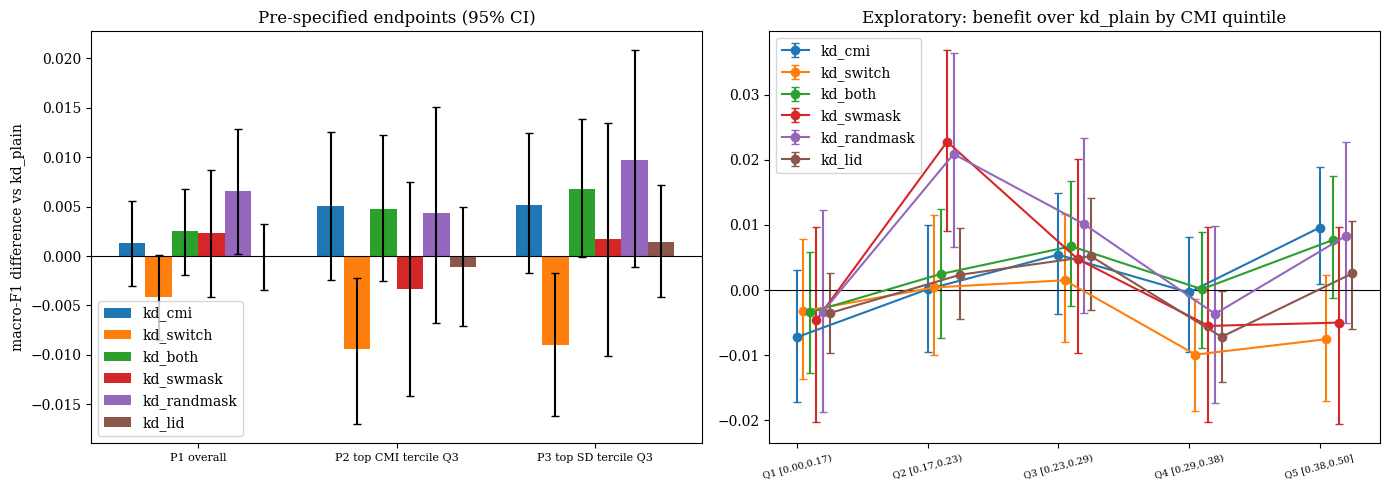

════ PHASE 4 DONE — SEND ALL ════ REPORT BACK ════ BLOCKS ABOVE ════
{
  "student_layers": 3,
  "layer_map": [
    3,
    7,
    11
  ],
  "student_params": 31393542,
  "teacher_f1": 0.7337417057843415,
  "arms": [
    "ce_only",
    "kd_plain",
    "kd_cmi",
    "kd_switch",
    "kd_both",
    "kd_swmask",
    "kd_randmask",
    "kd_lid"
  ],
  "seeds": [
    13,
    42,
    2024
  ],
  "hyperparams": {
    "lambda_cmi": 0.3,
    "w_min": 0.5,
    "w_max": 2.0,
    "mu_switch": 1.0,
    "p_mask_sw": 0.3,
    "n_transfer": 30460,
    "epochs": 3,
    "lr": 5e-05
  },
  "student_test_f1": {
    "ce_only": 0.6952336227647882,
    "kd_plain": 0.7053453311660712,
    "kd_cmi": 0.7066702492553688,
    "kd_switch": 0.701149620440087,
    "kd_both": 0.707904161468698,
    "kd_swmask": 0.707644828474605,
    "kd_randmask": 0.7119136273357104,
    "kd_lid": 0.7052071316406447
  },
  "headroom_teacher_minus_kd_plain": [
    0.02874497084047984,
    0.01591518267447617,
    0.041254221677660616
 

In [31]:
# CELL 8: Figures + save
# Figures and save.
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
pdf = prim_df.copy(); eps = list(dict.fromkeys(pdf.endpoint)); w_ = 0.8 / max(1, len(CAND))
for i, a in enumerate(CAND):
    t = pdf[pdf.arm == a].set_index("endpoint").loc[eps]
    ax[0].bar(np.arange(len(eps)) + i * w_, t.Δ_vs_kd_plain, w_, yerr=[t.Δ_vs_kd_plain - t.CI95_lo, t.CI95_hi - t.Δ_vs_kd_plain], capsize=3, label=a)
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_xticks(np.arange(len(eps)) + w_ * (len(CAND) - 1) / 2); ax[0].set_xticklabels([e.split(" [")[0] for e in eps], fontsize=8)
ax[0].set_ylabel("macro-F1 difference vs kd_plain"); ax[0].set_title("Pre-specified endpoints (95% CI)"); ax[0].legend()
t5 = strat_df[strat_df.cut == "CMI (quintile)"]
for a in CAND:
    ta = t5[t5.arm == a]; ax[1].errorbar(np.arange(len(ta)) + 0.05 * CAND.index(a), ta.delta, yerr=[ta.delta - ta.lo, ta.hi - ta.delta], fmt="o-", capsize=3, label=a)
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_xticks(np.arange(len(ta))); ax[1].set_xticklabels(ta.bin, fontsize=7, rotation=15)
ax[1].set_title("Exploratory: benefit over kd_plain by CMI quintile"); ax[1].legend()
plt.tight_layout(); (OUT_DIR / "figures").mkdir(exist_ok=True); plt.savefig(OUT_DIR / "figures" / "phase4_endpoints.png", dpi=150, bbox_inches="tight"); plt.show()

prim_df.to_csv(OUT_DIR / "phase4_primary_endpoints.csv", index=False); strat_df.to_csv(OUT_DIR / "phase4_exploratory_bins.csv", index=False)
for a, p in PROBS_ARM.items(): np.save(OUT_DIR / f"probs_L{STUDENT_LAYERS}_{a}_all_seeds.npy", p)
summary = {"student_layers": STUDENT_LAYERS, "layer_map": LAYER_MAP, "student_params": int(s_par), "teacher_f1": t_f1, "arms": list(PRED_ARM), "seeds": SEEDS,
           "hyperparams": {"lambda_cmi": LAMBDA_CMI, "w_min": W_MIN, "w_max": W_MAX, "mu_switch": MU_SWITCH, "p_mask_sw": P_MASK_SW, "n_transfer": int(len(transfer)), "epochs": EPOCHS, "lr": LR},
           "student_test_f1": {a: float(np.mean([macro_f1_np(y_te, PRED_ARM[a][k]) for k in range(S_[a])])) for a in PRED_ARM},
           "headroom_teacher_minus_kd_plain": [float(np.mean(hd))] + [float(x) for x in ci(hd)]}
(OUT_DIR / "phase4_summary.json").write_text(json.dumps(summary, indent=2))
print("=" * 70); print("════ PHASE 4 DONE — SEND ALL ════ REPORT BACK ════ BLOCKS ABOVE ════"); print("=" * 70)
print(json.dumps(summary, indent=2)); print("Saved to:", OUT_DIR)

In [32]:
# CELL 7: CPU Inference Benchmark
import time
import torch

print("=" * 70)
print("════ REPORT BACK: CPU INFERENCE BENCHMARK ════")
print("=" * 70)

# Force device to CPU to simulate edge/mobile deployment
cpu_device = torch.device("cpu")

# Move teacher to CPU
teacher_cpu = teacher.to(cpu_device)
teacher_cpu.eval()

# Build a fresh student architecture and move to CPU
student_cpu = build_student().to(cpu_device)
student_cpu.eval()

# Grab a single batch of data from the test loader
sample_batch = next(iter(te_loader4))
input_ids = sample_batch["input_ids"].to(cpu_device)
attention_mask = sample_batch["attention_mask"].to(cpu_device)
batch_size = input_ids.shape[0]

# FIX: Remap the input IDs for the Student's trimmed vocabulary
remap_cpu = remap_t.to(cpu_device)
student_input_ids = remap_cpu[input_ids]

def benchmark_cpu(model, inputs, mask, n_runs=30):
    # Warmup runs (not counted in time)
    with torch.no_grad():
        for _ in range(5):
            _ = model(input_ids=inputs, attention_mask=mask)

    # Actual timed benchmark
    start_time = time.perf_counter()
    with torch.no_grad():
        for _ in range(n_runs):
            _ = model(input_ids=inputs, attention_mask=mask)
    end_time = time.perf_counter()

    total_time = end_time - start_time
    avg_ms_per_batch = (total_time / n_runs) * 1000
    throughput = (n_runs * batch_size) / total_time
    return avg_ms_per_batch, throughput

print("Benchmarking Teacher (110.5M) on CPU...")
t_ms, t_sps = benchmark_cpu(teacher_cpu, input_ids, attention_mask)

print("Benchmarking Student (30.8M) on CPU...")
# Pass the remapped IDs to the student
s_ms, s_sps = benchmark_cpu(student_cpu, student_input_ids, attention_mask)

speedup = t_ms / s_ms

print("\n" + "─" * 40)
print(f"Batch Size: {batch_size} sentences")
print(f"Teacher: {t_ms:.1f} ms/batch | {t_sps:.1f} sentences/sec")
print(f"Student:  {s_ms:.1f} ms/batch | {s_sps:.1f} sentences/sec")
print(f"SPEEDUP: The 3-layer Student is {speedup:.2f}x faster on CPU.")
print("─" * 40)

# Move teacher back to GPU
teacher.to(DEVICE)

════ REPORT BACK: CPU INFERENCE BENCHMARK ════
Benchmarking Teacher (110.5M) on CPU...
Benchmarking Student (30.8M) on CPU...

────────────────────────────────────────
Batch Size: 128 sentences
Teacher: 16089.1 ms/batch | 8.0 sentences/sec
Student:  4049.8 ms/batch | 31.6 sentences/sec
SPEEDUP: The 3-layer Student is 3.97x faster on CPU.
────────────────────────────────────────


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [33]:
# CELL 8: Model RAM Footprint Benchmark

def get_model_memory_mb(model):
    # Calculate the exact memory taken by the model's weights and buffers
    mem_params = sum([param.nelement() * param.element_size() for param in model.parameters()])
    mem_buffers = sum([buf.nelement() * buf.element_size() for buf in model.buffers()])
    return (mem_params + mem_buffers) / (1024 ** 2) # Convert bytes to Megabytes

teacher_mb = get_model_memory_mb(teacher_cpu)
student_mb = get_model_memory_mb(student_cpu)

print("=" * 70)
print("════ REPORT BACK: RAM FOOTPRINT BENCHMARK ════")
print("=" * 70)
print(f"Teacher Model (110.5M): {teacher_mb:.2f} MB of RAM required")
print(f"Student Model (30.8M):   {student_mb:.2f} MB of RAM required")
print(f"RAM Reduction:           {teacher_mb / student_mb:.2f}x smaller footprint")
print("=" * 70)

════ REPORT BACK: RAM FOOTPRINT BENCHMARK ════
Teacher Model (110.5M): 417.66 MB of RAM required
Student Model (30.8M):   119.76 MB of RAM required
RAM Reduction:           3.49x smaller footprint


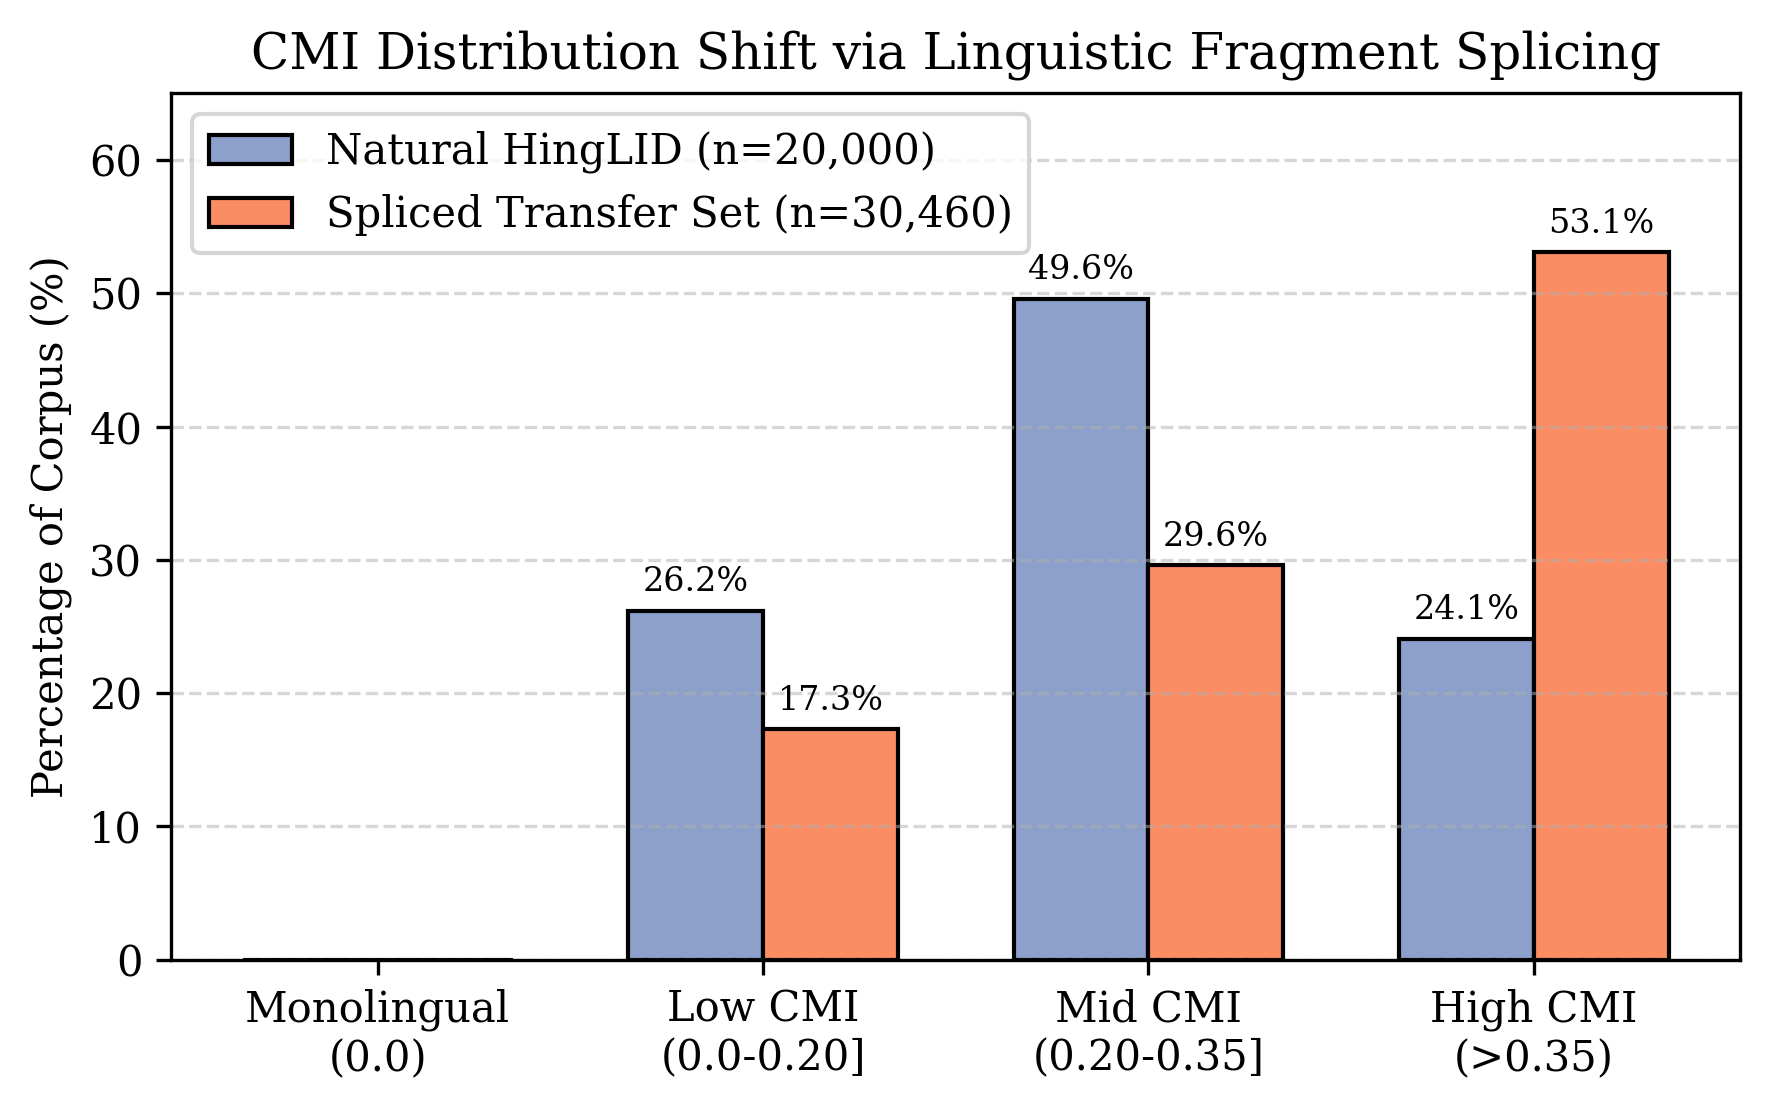

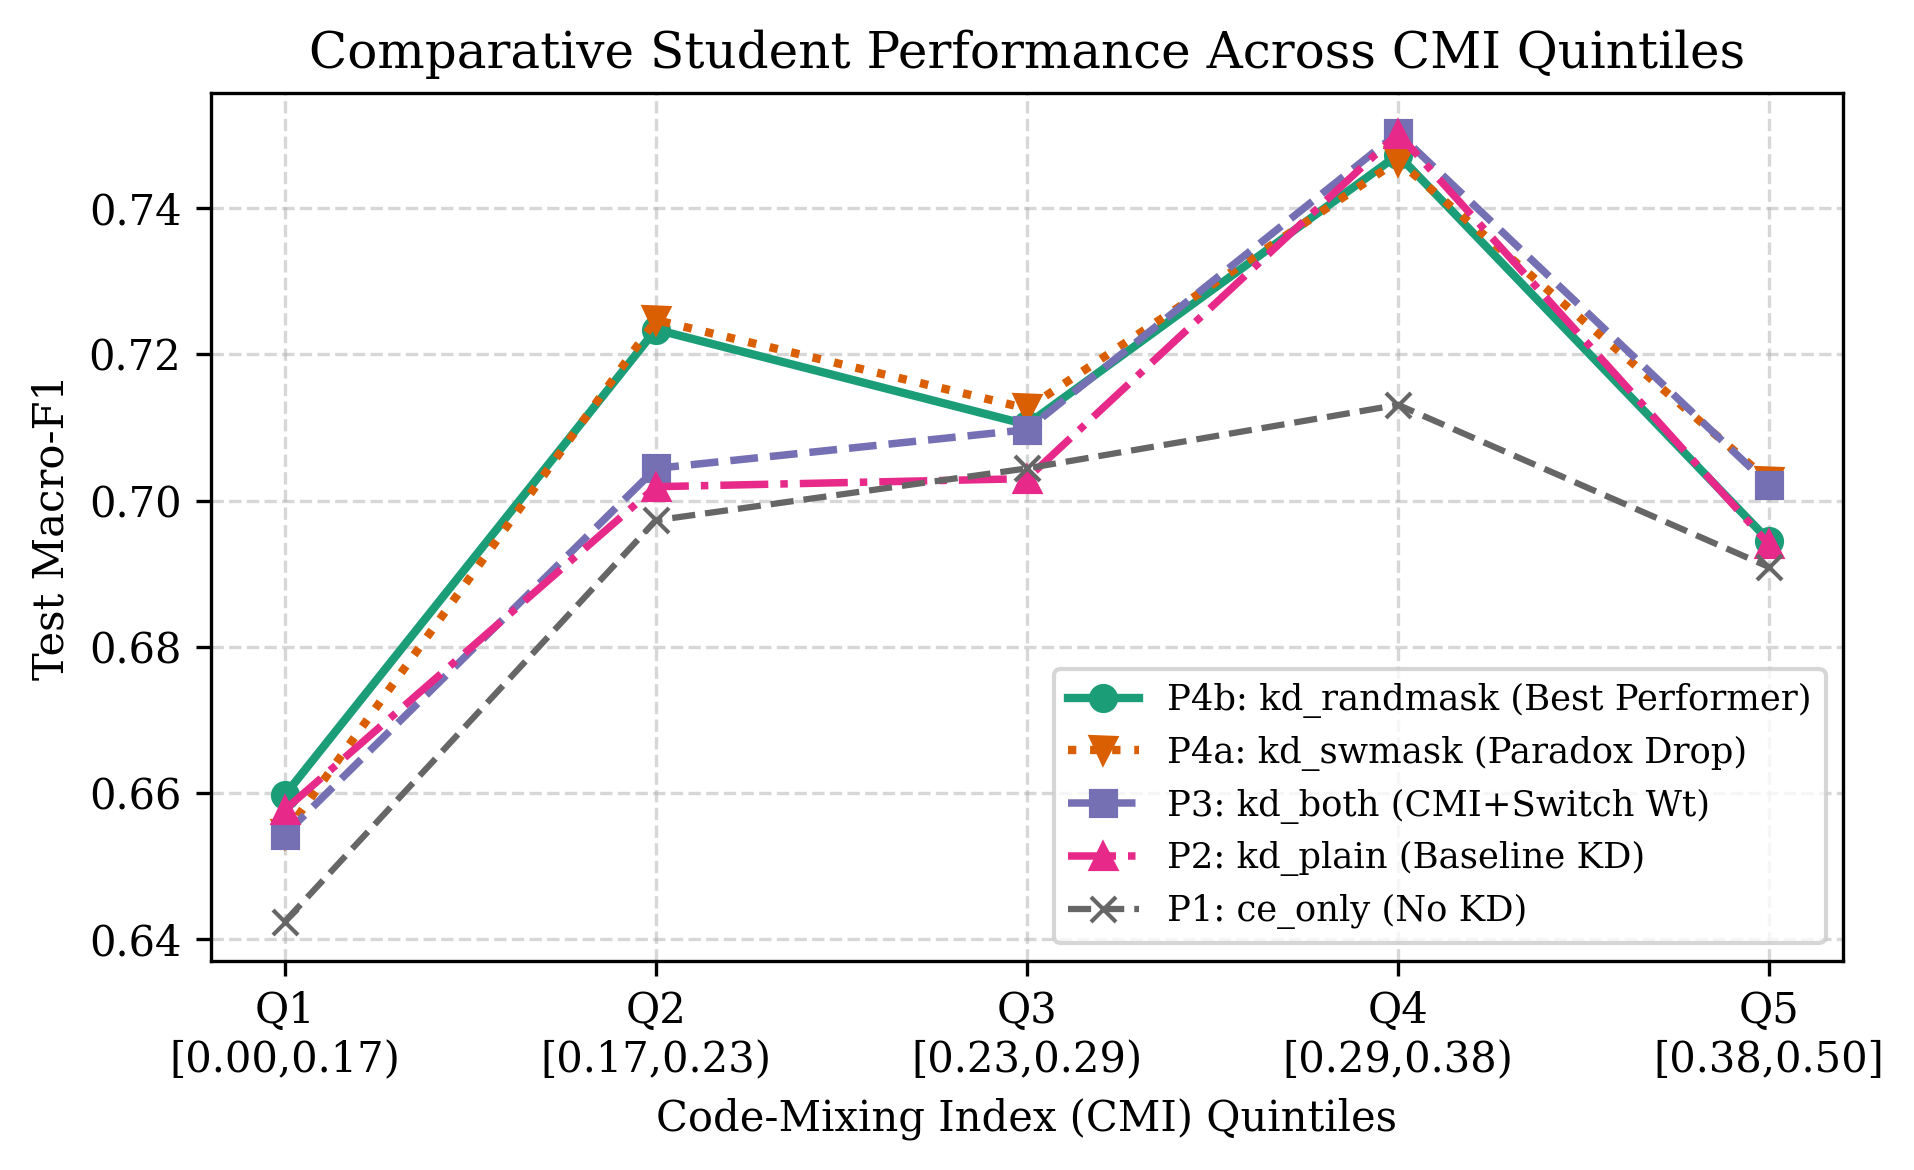

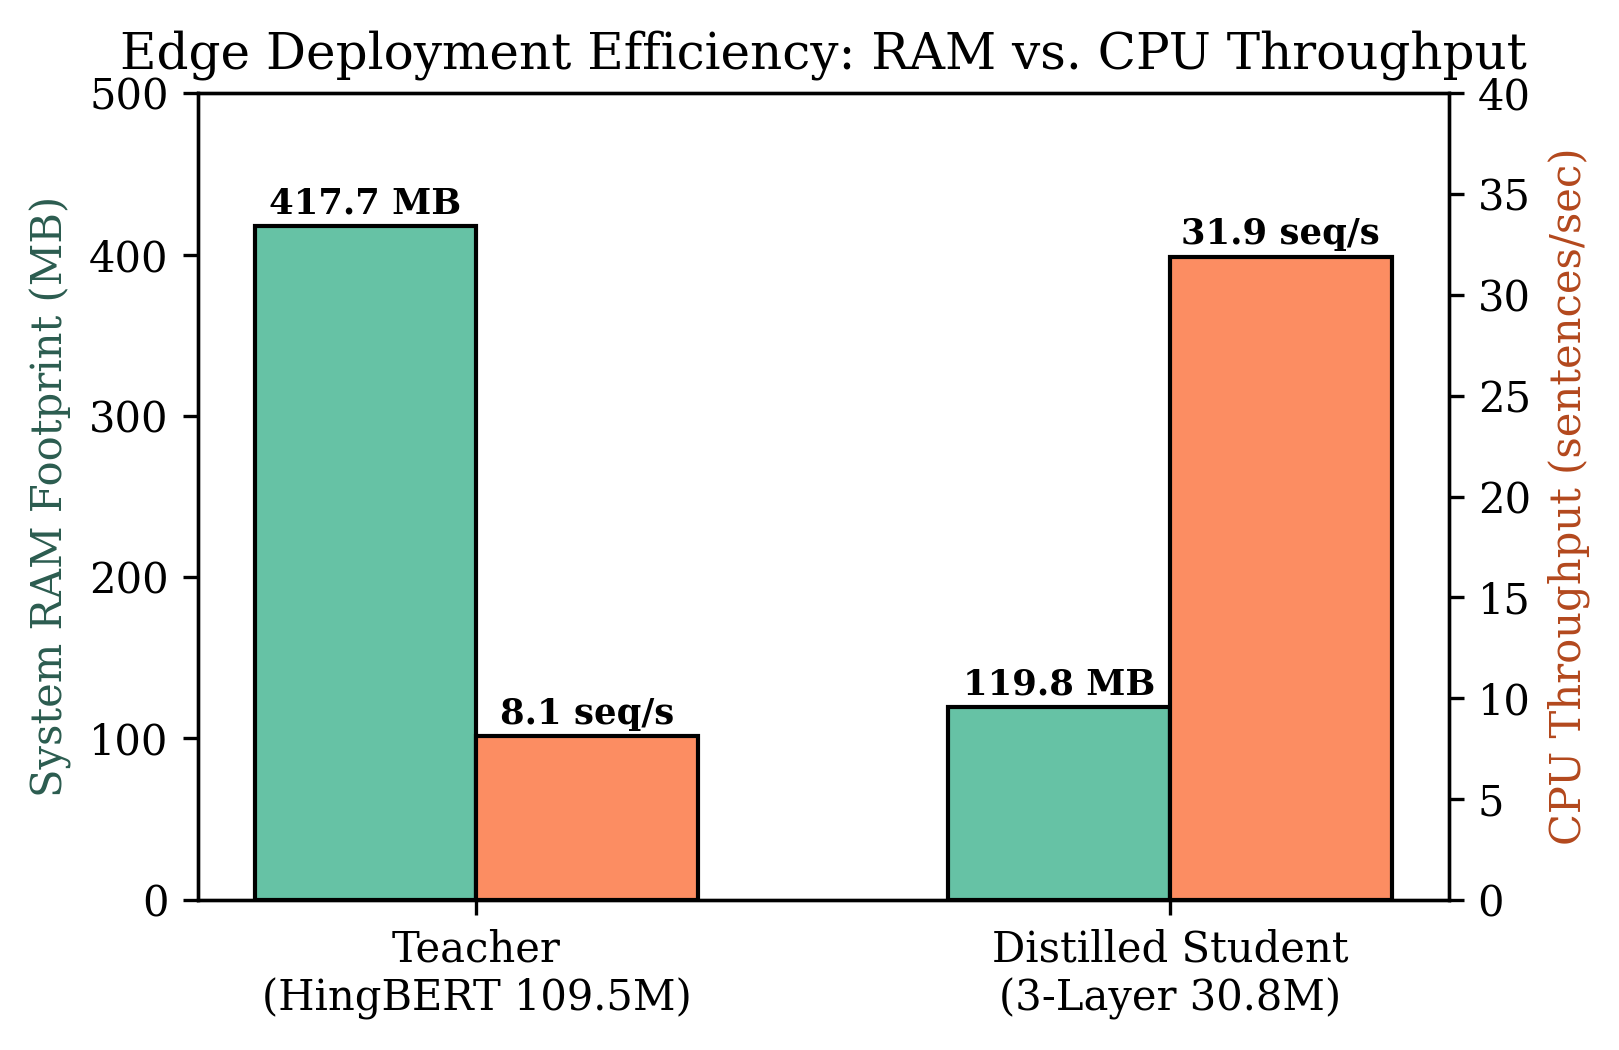

In [34]:
# CELL 9: Generate Publication-Ready IEEE Figures (Day 2)
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})

# ─── FIGURE 1: Transfer Set CMI Distribution Shift ───
bins = ['Monolingual\n(0.0)', 'Low CMI\n(0.0-0.20]', 'Mid CMI\n(0.20-0.35]', 'High CMI\n(>0.35)']
natural_shares = [0.0, 26.2, 49.6, 24.1]
synthetic_shares = [0.0, 17.3, 29.6, 53.1]

x = np.arange(len(bins))
width = 0.35

fig, ax = plt.subplots(figsize=(6, 3.8), dpi=300)
rects1 = ax.bar(x - width/2, natural_shares, width, label='Natural HingLID (n=20,000)', color='#8da0cb', edgecolor='black')
rects2 = ax.bar(x + width/2, synthetic_shares, width, label='Spliced Transfer Set (n=30,460)', color='#fc8d62', edgecolor='black')

ax.set_ylabel('Percentage of Corpus (%)')
ax.set_title('CMI Distribution Shift via Linguistic Fragment Splicing')
ax.set_xticks(x)
ax.set_xticklabels(bins)
ax.set_ylim(0, 65)
ax.legend(frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.5)

for rect in rects1 + rects2:
    h = rect.get_height()
    if h > 0:
        ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('fig1_cmi_distribution.png', dpi=300)
plt.show()

# ─── FIGURE 2: Macro-F1 Across CMI Quintiles (Q1 to Q5) ───
# Updated with exact Day 1 numbers
quintiles = ['Q1\n[0.00,0.17)', 'Q2\n[0.17,0.23)', 'Q3\n[0.23,0.29)', 'Q4\n[0.29,0.38)', 'Q5\n[0.38,0.50]']
kd_plain_q    = [0.6577, 0.7019, 0.7030, 0.7502, 0.6940]
kd_randmask_q = [0.6597, 0.7234, 0.7104, 0.7473, 0.6945]
kd_swmask_q   = [0.6544, 0.7247, 0.7126, 0.7465, 0.7027]
kd_both_q     = [0.6543, 0.7044, 0.7097, 0.7503, 0.7021]
ce_only_q     = [0.6424, 0.6973, 0.7044, 0.7131, 0.6909]

fig, ax = plt.subplots(figsize=(6.5, 4.0), dpi=300)
ax.plot(quintiles, kd_randmask_q, marker='o', linewidth=2, label='P4b: kd_randmask (Best Performer)', color='#1b9e77')
ax.plot(quintiles, kd_swmask_q, marker='v', linestyle=':', linewidth=2, label='P4a: kd_swmask (Paradox Drop)', color='#d95f02')
ax.plot(quintiles, kd_both_q, marker='s', linestyle='--', linewidth=1.8, label='P3: kd_both (CMI+Switch Wt)', color='#7570b3')
ax.plot(quintiles, kd_plain_q, marker='^', linestyle='-.', linewidth=1.8, label='P2: kd_plain (Baseline KD)', color='#e7298a')
ax.plot(quintiles, ce_only_q, marker='x', linestyle='--', linewidth=1.5, label='P1: ce_only (No KD)', color='#666666')

ax.set_ylabel('Test Macro-F1')
ax.set_xlabel('Code-Mixing Index (CMI) Quintiles')
ax.set_title('Comparative Student Performance Across CMI Quintiles')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower right', fontsize=8.5, frameon=True)
plt.tight_layout()
plt.savefig('fig2_quintile_comparison.png', dpi=300)
plt.show()

# ─── FIGURE 3: Hardware Edge Deployment Benchmark ───
fig, ax1 = plt.subplots(figsize=(5.5, 3.6), dpi=300)
models = ['Teacher\n(HingBERT 109.5M)', 'Distilled Student\n(3-Layer 30.8M)']
ram_mb = [417.66, 119.76]
throughput = [8.1, 31.9]

x = np.arange(len(models))
w = 0.32

b1 = ax1.bar(x - w/2, ram_mb, w, label='Static RAM (MB) [Lower is Better]', color='#66c2a5', edgecolor='black')
ax1.set_ylabel('System RAM Footprint (MB)', color='#2b5c4f')
ax1.set_ylim(0, 500)
ax1.set_xticks(x)
ax1.set_xticklabels(models)

ax2 = ax1.twinx()
b2 = ax2.bar(x + w/2, throughput, w, label='CPU Throughput (seq/s) [Higher is Better]', color='#fc8d62', edgecolor='black')
ax2.set_ylabel('CPU Throughput (sentences/sec)', color='#b3481d')
ax2.set_ylim(0, 40)

for rect in b1:
    ax1.annotate(f'{rect.get_height():.1f} MB', xy=(rect.get_x() + rect.get_width()/2, rect.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha='center', fontsize=8.5, fontweight='bold')
for rect in b2:
    ax2.annotate(f'{rect.get_height():.1f} seq/s', xy=(rect.get_x() + rect.get_width()/2, rect.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha='center', fontsize=8.5, fontweight='bold')

plt.title('Edge Deployment Efficiency: RAM vs. CPU Throughput')
plt.tight_layout()
plt.savefig('fig3_edge_hardware.png', dpi=300)
plt.show()

In [41]:
# CELL 10: Extract Examples for Qualitative Error Table
SEED_Q = 42
ARM_A, ARM_B = "kd_plain", "kd_swmask"
N_SHOW = 5
MIN_CMI, MIN_LANG = 0.30, 6          # keep only clearly code-mixed sentences

# Use in-memory probs; fall back to the saved .npy files if needed
def get_probs(arm):
    if "PROBS_ARM" in globals() and arm in PROBS_ARM:
        return PROBS_ARM[arm]
    return np.load(OUT_DIR / f"probs_L{STUDENT_LAYERS}_{arm}_all_seeds.npy")

si = SEEDS.index(SEED_Q)
pA = get_probs(ARM_A)[si].argmax(1)
pB = get_probs(ARM_B)[si].argmax(1)

mixed = (te_df.cmi_gold.values >= MIN_CMI) & (te_df.nlang_gold.values >= MIN_LANG)

def tagged(i):
    """Original tokens with language tags, e.g. 'movie/EN bahut/HI'; OTHER tokens left untagged."""
    return " ".join(t if g == "OTHER" else f"{t}/{g}" for t, g in zip(te_df.tokens.iloc[i], te_df.gold_tags.iloc[i]))

def show(idx, title):
    print(f"\n════ {title}: {len(idx)} examples (showing up to {N_SHOW}, highest CMI first) ════")
    idx = idx[np.argsort(-te_df.cmi_gold.values[idx])][:N_SHOW]
    for i in idx:
        print(f"Text:          {te_df.raw_text.iloc[i]}")
        print(f"Language tags: {tagged(i)}")
        print(f"CMI / SD:      {te_df.cmi_gold.iloc[i]:.2f} / {te_df.sd_gold.iloc[i]:.2f}")
        print(f"True label:    {LABELS[y_te[i]]}")
        print(f"{ARM_A:<14} {LABELS[pA[i]]}")
        print(f"{ARM_B:<14} {LABELS[pB[i]]}")
        print(f"Teacher:       {LABELS[P_T[i]]}")
        print("-" * 60)

a_only = np.where((pA == y_te) & (pB != y_te) & mixed)[0]   # ARM_A right, ARM_B wrong
b_only = np.where((pB == y_te) & (pA != y_te) & mixed)[0]   # ARM_B right, ARM_A wrong

print(f"Seed {SEED_Q}, code-mixed subset (CMI>={MIN_CMI}, lang tokens>={MIN_LANG}): {mixed.sum()} sentences")
show(a_only, f"{ARM_A} correct, {ARM_B} wrong")
show(b_only, f"{ARM_B} correct, {ARM_A} wrong")

Seed 42, code-mixed subset (CMI>=0.3, lang tokens>=6): 1165 sentences

════ kd_plain correct, kd_swmask wrong: 63 examples (showing up to 5, highest CMI first) ════
Text:          @ sumitkashyapjha What is this theory where everyone thinks â€œ lagta hai mujje chodke sabne bjp ko vote diya hai â€ and â€¦ https // t . co / btj3yA18mp
Language tags: @ sumitkashyapjha What/HI is/EN this/EN theory/EN where/EN everyone/EN thinks/EN â€œ lagta/HI hai/HI mujje/HI chodke/HI sabne/HI bjp/HI ko/HI vote/HI diya/HI hai/HI â€ and/EN â€¦ https/EN // t/EN . co/EN / btj3yA18mp/EN
CMI / SD:      0.50 / 0.14
True label:    neutral
kd_plain       neutral
kd_swmask      negative
Teacher:       neutral
------------------------------------------------------------
Text:          @ SanjayAzadSln Pura election he fake tha bhaiya
Language tags: @ SanjayAzadSln Pura/EN election/HI he/EN fake/EN tha/HI bhaiya/HI
CMI / SD:      0.50 / 0.60
True label:    negative
kd_plain       negative
kd_swmask      neutral
Teac

In [42]:
# CELL 10: Qualitative Error Extraction (no checkpoints needed)
from pathlib import Path
import numpy as np

SEED_Q = 42
ARM_A, ARM_B = "kd_plain", "kd_swmask"
N_SHOW = 5
MIN_CMI, MIN_LANG = 0.30, 6

# Sanity check: these come from Cells 1-2
for v in ["te_df", "y_te", "P_T", "LABELS", "SEEDS", "OUT_DIR", "STUDENT_LAYERS"]:
    assert v in globals(), f"{v} missing: re-run Cells 1-2 first (runtime may have reset)"

def get_probs(arm):
    if "PROBS_ARM" in globals() and arm in PROBS_ARM:
        return PROBS_ARM[arm]
    fn = f"probs_L{STUDENT_LAYERS}_{arm}_all_seeds.npy"
    for d in [Path(OUT_DIR), Path("phase4_outputs"), Path("/content/phase4_outputs"),
              Path("/content/drive/MyDrive/mixing_aware_kd/phase4")]:
        if (d / fn).exists():
            print("Loaded", d / fn); return np.load(d / fn)
    raise FileNotFoundError(f"{fn} not found. Re-run Cell 6 for {arm} (with Drive mounted this time).")

si = SEEDS.index(SEED_Q)
pA = get_probs(ARM_A)[si].argmax(1)
pB = get_probs(ARM_B)[si].argmax(1)
mixed = (te_df.cmi_gold.values >= MIN_CMI) & (te_df.nlang_gold.values >= MIN_LANG)

def tagged(i):
    return " ".join(t if g == "OTHER" else f"{t}/{g}"
                    for t, g in zip(te_df.tokens.iloc[i], te_df.gold_tags.iloc[i]))

def show(idx, title):
    print(f"\n════ {title}: {len(idx)} examples (showing up to {N_SHOW}, highest CMI first) ════")
    for i in idx[np.argsort(-te_df.cmi_gold.values[idx])][:N_SHOW]:
        print(f"Text:          {te_df.raw_text.iloc[i]}")
        print(f"Language tags: {tagged(i)}")
        print(f"CMI / SD:      {te_df.cmi_gold.iloc[i]:.2f} / {te_df.sd_gold.iloc[i]:.2f}")
        print(f"True label:    {LABELS[y_te[i]]}")
        print(f"{ARM_A:<14} {LABELS[pA[i]]}")
        print(f"{ARM_B:<14} {LABELS[pB[i]]}")
        print(f"Teacher:       {LABELS[P_T[i]]}")
        print("-" * 60)

a_only = np.where((pA == y_te) & (pB != y_te) & mixed)[0]
b_only = np.where((pB == y_te) & (pA != y_te) & mixed)[0]

print(f"Seed {SEED_Q}, code-mixed subset (CMI>={MIN_CMI}, lang tokens>={MIN_LANG}): {mixed.sum()} sentences")
print(f"{ARM_A} right / {ARM_B} wrong: {len(a_only)} | {ARM_B} right / {ARM_A} wrong: {len(b_only)}")
show(a_only, f"{ARM_A} correct, {ARM_B} wrong")
show(b_only, f"{ARM_B} correct, {ARM_A} wrong")

Seed 42, code-mixed subset (CMI>=0.3, lang tokens>=6): 1165 sentences
kd_plain right / kd_swmask wrong: 63 | kd_swmask right / kd_plain wrong: 62

════ kd_plain correct, kd_swmask wrong: 63 examples (showing up to 5, highest CMI first) ════
Text:          @ sumitkashyapjha What is this theory where everyone thinks â€œ lagta hai mujje chodke sabne bjp ko vote diya hai â€ and â€¦ https // t . co / btj3yA18mp
Language tags: @ sumitkashyapjha What/HI is/EN this/EN theory/EN where/EN everyone/EN thinks/EN â€œ lagta/HI hai/HI mujje/HI chodke/HI sabne/HI bjp/HI ko/HI vote/HI diya/HI hai/HI â€ and/EN â€¦ https/EN // t/EN . co/EN / btj3yA18mp/EN
CMI / SD:      0.50 / 0.14
True label:    neutral
kd_plain       neutral
kd_swmask      negative
Teacher:       neutral
------------------------------------------------------------
Text:          @ SanjayAzadSln Pura election he fake tha bhaiya
Language tags: @ SanjayAzadSln Pura/EN election/HI he/EN fake/EN tha/HI bhaiya/HI
CMI / SD:      0.50 / 0.60